In [1]:
from pathlib import Path
import sys

# Use the local working tree. Restart the kernel before running this cell.
LOCAL_RECTANGLE = Path('/Users/berni/PycharmProjects/Rectangle')
local_src = LOCAL_RECTANGLE / 'src'
if not (local_src / 'rectanglepy' / '__init__.py').is_file():
    raise FileNotFoundError(f'Local Rectangle package not found in {local_src}')
sys.path.insert(0, str(local_src))

import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

if not Path(rp.__file__).resolve().is_relative_to(local_src.resolve()):
    raise RuntimeError('rectanglepy is already loaded from another location. Restart the kernel and run this cell first.')
# __version__ comes from installed distribution metadata; __file__ verifies the source.
print('Rectangle source:', rp.__file__)
print('Rectangle distribution version:', rp.__version__)


Rectangle source: /Users/berni/PycharmProjects/Rectangle/src/rectanglepy/__init__.py
Rectangle distribution version: 1.6.0


# Figure 2

In [3]:
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
adata_hao_sub = anndata.read_h5ad('../data/fig2/haoSub_adata.h5ad')

In [4]:
adata_hao_sub.obs.value_counts()

cell_type       
Monocytes           4844
T cells CD4 conv    3566
T cells CD8         2361
NK cells            1801
B cells             1338
Tregs                251
mDC                  237
Platelet             212
pDC                   85
Plasma cells          36
ILC                   13
Name: count, dtype: int64

In [5]:
sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl.zip")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

## Figure 2A

In [6]:
# Load Bulks
bulks_chen = pd.read_csv("../data/fig2/bulks/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/fig2/bulks/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/fig2/finotello/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/fig2/bulks/bulks_hoek_tpm.csv", index_col=0)
bulks_morandini = pd.read_csv("../data/fig2/morandini/morandini_rework_tpm.csv.gz", index_col=0)
bulks_dietrich = pd.read_csv("../data/fig2/deconvME/dietrich_tpm.csv", index_col=0)



In [7]:
estimations_fino, signature_results_fino = rp.rectangle(adata_hao_sub, bulks_fino.T,)


2026-10-08 16:39:54.562 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 16:39:56.941 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:40:00.612 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:40:03.533 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 16:40:05.160 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 16:40:06.869 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:40:08.143 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 16:40:09.280 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:40:18.826 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.027472426488265998, Pearson R:0.9123159469511136 for p=0.05, lfc=1.7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:40:18.939 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-08 16:40:19.082 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02754013312534663, Pearson R:0.9124773032955845 for p=0.05, lfc=1.8


...

2026-10-08 16:40:20.422 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 55
2026-10-08 16:40:20.427 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:385 - Starting rectangle cluster analysis
2026-10-08 16:40:20.437 | INFO     | rectanglepy.pp.create_signature:_create_clustered_data:290 - Starting clustered analysis
2026-10-08 16:40:21.466 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:40:25.105 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 1
2026-10-08 16:40:26.537 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 2
2026-10-08 16:40:27.902 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 5
2026-10-08 16:40:29.507 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:40:30.694 | INFO     | rectanglep

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:40:36.843 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 7
2026-10-08 16:40:36.850 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 0
2026-10-08 16:40:36.859 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 8
2026-10-08 16:40:36.867 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 1
2026-10-08 16:40:36.876 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 6
2026-10-08 16:40:36.902 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 4
2026-10-08 16:40:36.903 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 3
2026-10-08 16:40:36.914 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 2
2026-10-08 16:40:36.927 | INFO   

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:40:37.327 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 8
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [8]:
estimations_fino.to_csv("../output/hao_estimations_fino.csv")


In [9]:
estimations_fino = pd.read_csv("../output/hao_estimations_fino.csv", index_col=0)

In [10]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T

In [11]:
gld_m, finotello_m = helper.match_dfs(finotello_gld, estimations_fino.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
finotello_m = finotello_m.sort_index(key=lambda x: x.str.lower())
evaluation_fintotello_rectangle = helper.create_evaluation_df(gld_m, finotello_m)
rsme_finotello_rectangle, r_finotello_rectangle, p_finotello_rectangle = helper.evaulate_total_df(
    evaluation_fintotello_rectangle)
rsmes_f_rectangle, ps_f_rectangle, rs_f_rectangle = helper.evaluate_by_cell_type(gld_m, finotello_m)

In [12]:
estimations_hoek, signature_results_hoek = rp.rectangle(adata_hao_sub, bulks_hoek.T)
estimations_hoek.to_csv("../output/hao_estimations_hoek.csv")

2026-10-08 16:40:40.357 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 12872 common genes between bulks and single-cell data
2026-10-08 16:40:42.799 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:40:46.164 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:40:47.407 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 16:40:49.048 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 16:40:50.745 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:40:51.944 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 16:40:53.013 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:41:02.629 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-08 16:41:02.762 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.027472426488265998, Pearson R:0.9123159469511136 for p=0.05, lfc=1.7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:41:02.888 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 40
2026-10-08 16:41:03.025 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.02754013312534663, Pearson R:0.9124773032955845 for p=0.05, lfc=1.8


...

2026-10-08 16:41:03.985 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 76
2026-10-08 16:41:04.161 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.032448846677238505, Pearson R:0.8804091284600971 for p=0.05, lfc=2.2
2026-10-08 16:41:04.163 | INFO     | rectanglepy.pp.create_signature:_de_analysis:232 - Optimization done
 Best cutoffs  p: 0.05 and lfc: 1.6


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:41:04.263 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 55
2026-10-08 16:41:04.269 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:385 - Starting rectangle cluster analysis
2026-10-08 16:41:04.284 | INFO     | rectanglepy.pp.create_signature:_create_clustered_data:290 - Starting clustered analysis
2026-10-08 16:41:05.766 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:41:08.746 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 1
2026-10-08 16:41:10.510 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 2
2026-10-08 16:41:12.346 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 5
2026-10-08 16:41:14.032 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:41:15.086 | INFO     | rectanglep

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:41:20.336 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 3
2026-10-08 16:41:20.365 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 4
2026-10-08 16:41:20.392 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 6
2026-10-08 16:41:20.397 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 0
2026-10-08 16:41:20.414 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 7
2026-10-08 16:41:20.418 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 5
2026-10-08 16:41:20.436 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 2
2026-10-08 16:41:20.447 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 1
/Users/berni/PycharmProjects/rec

In [13]:
estimations_hoek = pd.read_csv("../output/hao_estimations_hoek.csv", index_col=0)

In [14]:
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T


estimations_hoek['T cells'] = estimations_hoek['T cells CD4 conv'] + estimations_hoek['T cells CD8'] + estimations_hoek[
    'Tregs']

estimations_hoek = estimations_hoek.T

gld_hoek_m, hoek_m = helper.match_dfs(hoek_gld, estimations_hoek)
gld_hoek_m = gld_hoek_m.sort_index(key=lambda x: x.str.lower())
hoek_m = hoek_m.sort_index(key=lambda x: x.str.lower())
evaluation_hoek = helper.create_evaluation_df(gld_hoek_m, hoek_m)
rsme_hoek, r_hoek, p_hoek = helper.evaulate_total_df(evaluation_hoek)
rsmes_h, ps_h, rs_h = helper.evaluate_by_cell_type(gld_hoek_m, hoek_m)

In [15]:
estimations_chen, signatures_chen  = rp.rectangle(adata_muris, bulks_chen.T)
estimations_chen.to_csv("../output/muris_estimations_chen.csv")

2026-10-08 16:41:22.816 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 10978 common genes between bulks and single-cell data
2026-10-08 16:41:24.080 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:41:26.030 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:41:26.883 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Macrophages
2026-10-08 16:41:28.080 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:41:28.849 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for T cells CD4 conv
2026-10-08 16:41:29.528 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for T cells CD8
2026-10-08 16:41:30.252 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Tregs

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:41:34.226 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.05484978171640786, Pearson R:0.8181267793877309 for p=0.05, lfc=1.7
2026-10-08 16:41:34.303 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25
2026-10-08 16:41:34.403 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.055333712000808215, Pearson R:0.815328135180826 for p=0.05, lfc=1.8


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:41:34.469 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25
2026-10-08 16:41:34.598 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.057064560574184214, Pearson R:0.8050775242147916 for p=0.05, lfc=1.9
2026-10-08 16:41:34.659 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25


...

2026-10-08 16:41:35.841 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:41:38.126 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 1
2026-10-08 16:41:38.766 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Macrophages
2026-10-08 16:41:39.443 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:41:40.162 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for mDC
2026-10-08 16:41:41.254 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 24
2026-10-08 16:41:41.274 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 0
2026-10-08 16:41:41.281 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 1
2026-10-08 16:41:41.287 | INFO     | rectanglepy.tl.deconv

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:41:41.580 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 5
2026-10-08 16:41:41.611 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 6
2026-10-08 16:41:41.619 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 8
2026-10-08 16:41:41.634 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 3
2026-10-08 16:41:41.637 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 4
2026-10-08 16:41:41.643 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 9
2026-10-08 16:41:41.645 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 7
2026-10-08 16:41:41.646 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 2
2026-10-08 16:41:41.652 | INFO    

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:41:41.789 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 9
2026-10-08 16:41:41.792 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 10
2026-10-08 16:41:41.798 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 8
2026-10-08 16:41:41.801 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 11
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [16]:
estimations_chen= pd.read_csv("../output/muris_estimations_chen.csv", index_col=0)

In [17]:
chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
chen_t = estimations_chen
chen_t['T cells CD4 Total'] = chen_t['T cells CD4 conv'] + chen_t['Tregs']
chen_m, gld_m = helper.match_dfs(chen_t,chen_gld)
# sort alphabetically reverse
gld_m = gld_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
chen_m = chen_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
evaluation_chen = helper.create_evaluation_df(gld_m.T, chen_m.T)
# sort by index alphabetically ignore case
evaluation_chen = evaluation_chen.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_chen, r_chen, p_chen = helper.evaulate_total_df(evaluation_chen)
rsmes_chen, ps_chen, rs_chen = helper.evaluate_by_cell_type(gld_m.T, chen_m.T)


In [18]:
estimations_peti, signatures_peti = rp.rectangle(adata_muris, bulks_peti.T)
estimations_peti.to_csv('../output/muris_estimations_peti.csv')

2026-10-08 16:41:43.700 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 10978 common genes between bulks and single-cell data
2026-10-08 16:41:45.060 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:41:47.207 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:41:47.941 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Macrophages
2026-10-08 16:41:48.809 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:41:49.570 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for T cells CD4 conv
2026-10-08 16:41:50.290 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for T cells CD8
2026-10-08 16:41:51.050 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Tregs

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:41:54.574 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.05484978171640786, Pearson R:0.8181267793877309 for p=0.05, lfc=1.7
2026-10-08 16:41:54.625 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25
2026-10-08 16:41:54.720 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.055333712000808215, Pearson R:0.815328135180826 for p=0.05, lfc=1.8


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:41:54.791 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25
2026-10-08 16:41:54.877 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.057064560574184214, Pearson R:0.8050775242147916 for p=0.05, lfc=1.9
2026-10-08 16:41:54.933 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 25


...

2026-10-08 16:41:56.347 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:41:58.478 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for 1
2026-10-08 16:41:59.150 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Macrophages
2026-10-08 16:41:59.822 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:42:00.481 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for mDC
2026-10-08 16:42:01.569 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 24
2026-10-08 16:42:01.591 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 0
2026-10-08 16:42:01.596 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 1
2026-10-08 16:42:01.607 | INFO     | rectanglepy.tl.deconv

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:42:01.884 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 1
2026-10-08 16:42:01.891 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 8
2026-10-08 16:42:01.896 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 2
2026-10-08 16:42:01.899 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 0
2026-10-08 16:42:01.904 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 9
2026-10-08 16:42:01.928 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 10
2026-10-08 16:42:01.932 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 3
2026-10-08 16:42:01.939 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 11
2026-10-08 16:42:01.987 | INFO    

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:42:02.124 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 11
2026-10-08 16:42:02.135 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 10
2026-10-08 16:42:02.154 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 9
2026-10-08 16:42:02.193 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 8
2026-10-08 16:42:02.203 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 12
2026-10-08 16:42:02.222 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 13
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/nu

In [19]:
estimations_peti = pd.read_csv('../output/muris_estimations_peti.csv', index_col=0)

In [20]:
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)

# replace nan with 0
petitprez_gld = petitprez_gld.fillna(0)

petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
# drop columns
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

# sort by index alphabetically ignore case
petitprez_gld = petitprez_gld.sort_index(key=lambda x: x.str.lower())
estimations_peti = estimations_peti.sort_index(key=lambda x: x.str.lower())


gld_m, petitprez_m = helper.match_dfs(petitprez_gld, estimations_peti)
evaluation_petitprez = helper.create_evaluation_df(gld_m.T, petitprez_m.T)
# sort by index alphabetically ignore case
evaluation_petitprez = evaluation_petitprez.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_peptirez, r_peptirez, p_peptirez = helper.evaulate_total_df(evaluation_petitprez)
rsmes_pept, ps_pept, rs_pept = helper.evaluate_by_cell_type(gld_m.T, petitprez_m.T)


In [21]:
estimations_morandini, signatures_morandini = rp.rectangle(adata_hao_sub, bulks_morandini.T)


2026-10-08 16:42:04.766 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 14700 common genes between bulks and single-cell data
2026-10-08 16:42:07.640 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:42:11.457 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:42:12.760 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 16:42:14.505 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 16:42:16.320 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:42:17.624 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 16:42:18.876 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:42:30.371 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77
2026-10-08 16:42:30.523 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.07197441491827943, Pearson R:0.5456155885219818 for p=0.05, lfc=1.7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:42:30.641 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77
2026-10-08 16:42:30.821 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.07269478521105056, Pearson R:0.542261235658128 for p=0.05, lfc=1.8


...

2026-10-08 16:43:02.128 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 148
2026-10-08 16:43:02.145 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 149
2026-10-08 16:43:02.150 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 150
2026-10-08 16:43:02.153 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 156
2026-10-08 16:43:02.167 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 157
2026-10-08 16:43:02.177 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 158
2026-10-08 16:43:02.241 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 151


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:43:02.498 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 152
2026-10-08 16:43:02.588 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 155
2026-10-08 16:43:02.630 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 153
2026-10-08 16:43:02.643 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 154
2026-10-08 16:43:02.691 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 156


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:43:02.777 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 158
2026-10-08 16:43:02.793 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 157
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [22]:
estimations_morandini.to_csv('../output/hao_estimations_morandini.csv')

In [23]:
estimations_morandini = pd.read_csv('../output/hao_estimations_morandini.csv', index_col=0)
estimations_morandini['T cells CD4'] = estimations_morandini['T cells CD4 conv']
estimations_morandini['T cells'] = estimations_morandini['T cells CD4 conv'] + estimations_morandini['T cells CD8'] + estimations_morandini[
    'Tregs']
estimations_morandini['Lymphocytes'] = estimations_morandini['T cells'] + estimations_morandini['NK cells'] + estimations_morandini['ILC'] + estimations_morandini['B cells'] + estimations_morandini['Plasma cells']
estimations_morandini = estimations_morandini.T

In [24]:
morandini_facs = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
morandini_facs = morandini_facs.T



In [25]:
morandini_facs.columns

Index(['Monocytes', 'Granulocytes', 'Lymphocytes', 'B cells', 'NK cells',
       'T cells', 'T cells CD4', 'T cells CD8'],
      dtype='object')

In [26]:
gld_m, morandini_m = helper.match_dfs(morandini_facs.T, estimations_morandini)

In [27]:

gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
morandini_m = morandini_m.sort_index(key=lambda x: x.str.lower())
evaluation_morandini = helper.create_evaluation_df(gld_m, morandini_m)
rsme_morandini, r_morandini, p_morandini = helper.evaulate_total_df(evaluation_morandini)
rsmes_morandini, ps_morandini, rs_morandini = helper.evaluate_by_cell_type(gld_m, morandini_m)


In [28]:
import glob
import os

dietrich_facs = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)

In [29]:
dietrich_facs.index


Index(['B cells', 'Monocytes', 'T cells', 'other', 'T cells CD4 conv',
       'T cells CD8', 'mDC', 'NK cells'],
      dtype='object')

In [30]:
dietrich_estimations, dietrich_signatures = rp.rectangle(adata_hao_sub, bulks_dietrich.T)
dietrich_estimations.to_csv('../output/hao_estimations_dietrich.csv')

2026-10-08 16:43:05.917 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:355 - Using 14703 common genes between bulks and single-cell data
2026-10-08 16:43:08.131 | INFO     | rectanglepy.pp.create_signature:_de_analysis:209 - Starting DE analysis
2026-10-08 16:43:12.184 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for B cells
2026-10-08 16:43:13.275 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for ILC
2026-10-08 16:43:15.313 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Monocytes
2026-10-08 16:43:17.110 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for NK cells
2026-10-08 16:43:18.382 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Plasma cells
2026-10-08 16:43:19.473 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:152 - Running DE analysis for Platelet
2026-10-08

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:43:30.997 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77
2026-10-08 16:43:31.144 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.0719771917184435, Pearson R:0.5462312227560175 for p=0.05, lfc=1.7


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point


2026-10-08 16:43:31.230 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77
2026-10-08 16:43:31.375 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:460 - RMSE:0.0727262902291622, Pearson R:0.542594378560346 for p=0.05, lfc=1.8
2026-10-08 16:43:31.466 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:249 - Optimal condition number: 77


...

2026-10-08 16:43:55.665 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 34
2026-10-08 16:43:55.701 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 42
2026-10-08 16:43:55.770 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 35
2026-10-08 16:43:55.789 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 43
2026-10-08 16:43:55.816 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 36
2026-10-08 16:43:55.832 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 44


Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:43:55.878 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 39
2026-10-08 16:43:55.889 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 37
2026-10-08 16:43:55.897 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 45
2026-10-08 16:43:55.912 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 46
2026-10-08 16:43:55.936 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 38
2026-10-08 16:43:55.955 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 47
2026-10-08 16:43:56.077 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 40
2026-10-08 16:43:56.102 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 48
2026-10-08 16:43:56.260 | IN

Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optimal point
Polishing not needed - no active set detected at optima

2026-10-08 16:43:56.651 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 44
2026-10-08 16:43:56.668 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 46
2026-10-08 16:43:56.683 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 52
2026-10-08 16:43:56.714 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 45
2026-10-08 16:43:56.715 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 53
2026-10-08 16:43:56.724 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 54
2026-10-08 16:43:56.751 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:434 - Finished deconvolution for bulk: 47
2026-10-08 16:43:56.770 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:431 - Deconvolute fractions for bulk: 55
2026-10-08 16:43:56.939 | IN

In [31]:
dietrich_facs = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
dietrich_estimations = pd.read_csv('../output/hao_estimations_dietrich.csv', index_col=0)
dietrich_facs = dietrich_facs[dietrich_facs.index != 'T cells']

gld_m, method_m = helper.match_dfs(dietrich_facs, dietrich_estimations.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
method_m = method_m.sort_index(key=lambda x: x.str.lower())

evaluation_method = helper.create_evaluation_df(gld_m, method_m)
rmse_dietrich, r_dietrich, p_dietrich = helper.evaulate_total_df(evaluation_method)
rsmes_dietrich, ps_dietrich, rs_dietrich = helper.evaluate_by_cell_type(gld_m, method_m)

# Figure 2B

In [32]:
corr_df_fino = pd.DataFrame(index=finotello_m.index, data=rs_f_rectangle)
corr_df_pept = pd.DataFrame(index=petitprez_m.T.index, data=rs_pept)
corr_df_chen = pd.DataFrame(index=chen_m.T.index, data=rs_chen)
corr_df_hoek = pd.DataFrame(index=hoek_m.index, data=rs_h)
corr_df_morandini = pd.DataFrame(index=morandini_m.index, data=rs_morandini)
corr_df_dietrich = pd.DataFrame(index=gld_m.index, data=rs_dietrich)

rmse_df_fino = pd.DataFrame(index=finotello_m.index, data=rsmes_f_rectangle)
rmse_df_pept = pd.DataFrame(index=petitprez_m.T.index, data=rsmes_pept)
rmse_df_chen = pd.DataFrame(index=chen_m.T.index, data=rsmes_chen)
rmse_df_hoek = pd.DataFrame(index=hoek_m.index, data=rsmes_h)

rmse_df_morandini = pd.DataFrame(index=morandini_m.index, data=rsmes_morandini)
rmse_df_dietrich = pd.DataFrame(index=gld_m.index, data=rsmes_dietrich)


<Figure size 640x480 with 0 Axes>

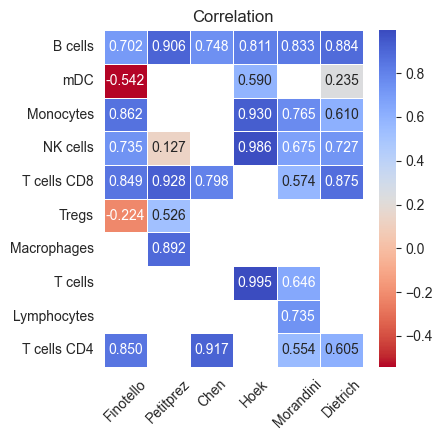

In [33]:
df_cor = pd.concat([corr_df_fino, corr_df_pept, corr_df_chen, corr_df_hoek, corr_df_morandini, corr_df_dietrich], axis=1)
df_cor.columns = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Dietrich']
df_cor = df_cor.T
cd4_components = df_cor[['T cells CD4 Total', 'T cells CD4 conv']].sum(axis=1, min_count=1)
if 'T cells CD4' in df_cor.columns:
    df_cor['T cells CD4'] = df_cor['T cells CD4'].combine_first(cd4_components)
else:
    df_cor['T cells CD4'] = cd4_components
df_cor = df_cor.drop(columns=['T cells CD4 Total', 'T cells CD4 conv'], errors='ignore')
plt.figure(facecolor='white')
# size
plt.figure(figsize=(4.5, 4.5))
# Plot the first heatmap
import seaborn as sns
sns.set_style("white")
sns.heatmap(df_cor.T, annot=True, cmap='coolwarm_r', fmt=".3f", linewidths=.5)
plt.title('Correlation')
#rotating the x-axis labels
plt.xticks(rotation=45)


# Adjust spacing between subplots
plt.tight_layout()


# Display the subplots
plt.show()



<Figure size 640x480 with 0 Axes>

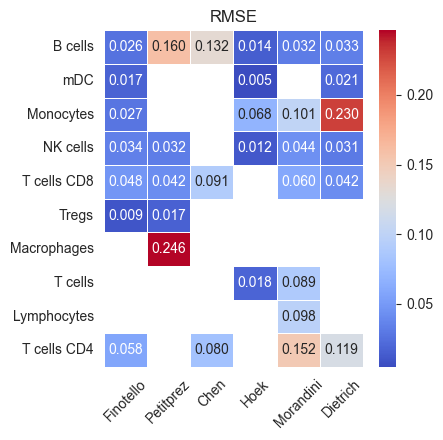

In [34]:
df_rmse = pd.concat([rmse_df_fino, rmse_df_pept, rmse_df_chen, rmse_df_hoek, rmse_df_morandini, rmse_df_dietrich], axis=1)
df_rmse.columns = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Dietrich']
df_rmse = df_rmse.T
cd4_components = df_rmse[['T cells CD4 Total', 'T cells CD4 conv']].sum(axis=1, min_count=1)
if 'T cells CD4' in df_rmse.columns:
    df_rmse['T cells CD4'] = df_rmse['T cells CD4'].combine_first(cd4_components)
else:
    df_rmse['T cells CD4'] = cd4_components
df_rmse = df_rmse.drop(columns=['T cells CD4 Total', 'T cells CD4 conv'], errors='ignore')
plt.figure(facecolor='white')
# size
plt.figure(figsize=(4.5, 4.5))
# Plot the first heatma
import seaborn as sns
sns.set_style("white")

sns.heatmap(df_rmse.T, annot=True, cmap='coolwarm', fmt=".3f", linewidths=.5)
plt.title('RMSE')
#rotating the x-axis labels
plt.xticks(rotation=45)


# Adjust spacing between subplots
plt.tight_layout()


In [35]:
# Combined Figure 2B table for manuscript copying
methods = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Dietrich']

fig2b_all_metrics = pd.DataFrame(
    [[
        r_finotello_rectangle, rsme_finotello_rectangle,
        r_peptirez, rsme_peptirez,
        r_chen, rsme_chen,
        r_hoek, rsme_hoek,
        r_morandini, rsme_morandini,
        r_dietrich, rmse_dietrich,
    ]],
    index=['All cell types'],
    columns=pd.MultiIndex.from_product([methods, ['Correlation', 'RMSE']])
)

fig2b_combined_table = pd.concat(
    {'Correlation': df_cor.T, 'RMSE': df_rmse.T},
    axis=1
).swaplevel(0, 1, axis=1)

fig2b_combined_table = fig2b_combined_table.loc[
    :,
    pd.MultiIndex.from_product([methods, ['Correlation', 'RMSE']])
]
fig2b_combined_table = pd.concat([fig2b_all_metrics, fig2b_combined_table])
fig2b_combined_table = fig2b_combined_table.round(3)
fig2b_combined_table.index.name = 'Cell type'

# Flat headers paste cleanly into Google Docs as a table.
fig2b_combined_table_flat = fig2b_combined_table.copy()
fig2b_combined_table_flat.columns = [
    f'{method} {metric}' for method, metric in fig2b_combined_table_flat.columns
]

fig2b_combined_table_flat.to_csv('../output/suppl_table_2.csv', na_rep='')

fig2b_combined_table_flat

,Finotello Correlation,Finotello RMSE,Petitprez Correlation,Petitprez RMSE,Chen Correlation,Chen RMSE,Hoek Correlation,Hoek RMSE,Morandini Correlation,Morandini RMSE,Dietrich Correlation,Dietrich RMSE
Cell type,,,,,,,,,,,,
All cell types,0.954,0.035,0.866,0.134,0.851,0.104,0.989,0.033,0.935,0.090,0.647,0.109
B cells,0.702,0.026,0.906,0.160,0.748,0.132,0.811,0.014,0.833,0.032,0.884,0.033
mDC,-0.542,0.017,NaN,NaN,NaN,NaN,0.590,0.005,NaN,NaN,0.235,0.021
Monocytes,0.862,0.027,NaN,NaN,NaN,NaN,0.930,0.068,0.765,0.101,0.610,0.230
NK cells,0.735,0.034,0.127,0.032,NaN,NaN,0.986,0.012,0.675,0.044,0.727,0.031
T cells CD8,0.849,0.048,0.928,0.042,0.798,0.091,NaN,NaN,0.574,0.060,0.875,0.042
Tregs,-0.224,0.009,0.526,0.017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Macrophages,NaN,NaN,0.892,0.246,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T cells,NaN,NaN,NaN,NaN,NaN,NaN,0.995,0.018,0.646,0.089,NaN,NaN


In [2]:
csv_path = '../data/fig2/cell_type_level_performance_metrics.csv'

bulk_map = {
    'Chen': 'chen',
    'Petitprez': 'petitprez',
    'Hoek': 'hoek',
    'Finotello': 'finotello',
    'Morandini': 'morandini',
    'Altman': 'altman'
}

cell_type_map = {
    'T cells CD4': 'CD4 T cells',
    'T cells CD8': 'CD8 T cells',
    'Neutrophilss': 'Neutrophils'
}

import glob
import os

morandini_results_root = '../data/fig2/results_main_morandini_ncbi'

def load_morandini_cell_type_metrics(results_root=morandini_results_root):
    rows = []
    for cor_path in sorted(glob.glob(os.path.join(results_root, '*', 'cor_cell_type.csv'))):
        method_name = os.path.basename(os.path.dirname(cor_path)).split('_')[0].lower()
        rmse_path = os.path.join(os.path.dirname(cor_path), 'rmse_cell_type.csv')
        cor_df = pd.read_csv(cor_path)[['cell_type', 'cor']]
        rmse_df = pd.read_csv(rmse_path)[['cell_type', 'RMSE']]
        method_metrics = cor_df.merge(rmse_df, on='cell_type', how='inner')
        method_metrics['cell_type'] = method_metrics['cell_type'].replace(cell_type_map)
        method_metrics['method'] = method_name
        method_metrics['bulk_ds'] = 'morandini'
        rows.append(method_metrics[['cell_type', 'method', 'bulk_ds', 'cor', 'RMSE']])
    if not rows:
        raise FileNotFoundError(f'No Morandini metric CSVs found under {results_root}')
    return pd.concat(rows, ignore_index=True)


In [3]:

cor_long = df_cor.stack(dropna=True).rename('cor').reset_index()
cor_long.columns = ['bulk_ds', 'cell_type', 'cor']

rmse_long = df_rmse.stack(dropna=True).rename('RMSE').reset_index()
rmse_long.columns = ['bulk_ds', 'cell_type', 'RMSE']

rectangle_results = cor_long.merge(rmse_long, on=['bulk_ds', 'cell_type'], how='inner')
rectangle_results['bulk_ds'] = rectangle_results['bulk_ds'].map(bulk_map).fillna(rectangle_results['bulk_ds']).str.lower()
rectangle_results['cell_type'] = rectangle_results['cell_type'].replace(cell_type_map)
rectangle_results['method'] = 'rectangle'
rectangle_results = rectangle_results[['cell_type', 'method', 'bulk_ds', 'cor', 'RMSE']]
rectangle_results = rectangle_results.dropna(subset=['cor', 'RMSE'])

all_metrics = pd.read_csv(csv_path)
morandini_method_metrics = load_morandini_cell_type_metrics()
all_metrics = all_metrics[~((all_metrics['bulk_ds'].str.lower() == 'morandini') & (all_metrics['method'].str.lower() != 'rectangle'))]
all_metrics = pd.concat([all_metrics, morandini_method_metrics], ignore_index=True)
all_metrics = all_metrics[all_metrics['method'].str.lower() != 'rectangle']
all_metrics_updated = pd.concat([all_metrics, rectangle_results], ignore_index=True)
all_metrics_updated = all_metrics_updated.sort_values(['cell_type', 'bulk_ds', 'method']).reset_index(drop=True)

all_metrics_updated.to_csv(csv_path, index=False)
all_metrics_updated[all_metrics_updated['method'] == 'rectangle']



NameError: name 'df_cor' is not defined

In [38]:
# celltype specific plot all methods

## Fig 2c



In [45]:
all_meths = pd.read_csv('../data/cor_rmse_all.csv', sep=';')
# replace ',' with '.'
all_meths['Correlation'] = all_meths['Cor'].str.replace(',', '.').astype(float)
all_meths['RMSE'] = all_meths['RMSE'].str.replace(',', '.').astype(float)

all_meths_chen = all_meths[all_meths['Set'] == 'Chen']
all_meths_fino = all_meths[all_meths['Set'] == 'Finotello']
all_meths_hoek = all_meths[all_meths['Set'] == 'Hoek']
all_meths_peti = all_meths[all_meths['Set'] == 'Petitprez']

morandini_overall = load_morandini_cell_type_metrics()
morandini_overall = morandini_overall[morandini_overall['cell_type'] == 'all'].copy()
morandini_overall['Method'] = morandini_overall['method']
morandini_overall['Set'] = 'Morandini'
morandini_overall['Cor'] = morandini_overall['cor']
morandini_overall['Correlation'] = morandini_overall['cor']
# Refresh Rectangle's overall score from the current Morandini evaluation.
rectangle_morandini = pd.DataFrame([{
    'Method': 'rectangle',
    'Set': 'Morandini',
    'Cor': r_morandini,
    'Correlation': r_morandini,
    'RMSE': rsme_morandini,
}])
all_meths_morandini = pd.concat(
    [morandini_overall[['Method', 'Set', 'Cor', 'Correlation', 'RMSE']], rectangle_morandini],
    ignore_index=True
)


In [40]:
method_palette = {
    "autogenes": "#66C2A5",
    "bayesprism": "#FC8D62",
    "bisque": "#8DA0CB",
    "cibersortx": "#E78AC3",
    "dwls": "#A6D854",
    "music": "#FFD92F",
    "scaden": "#E5C494",
    "scdc": "#B3B3B3",
    "rectangle": "#000000"
}

color_palette = [method_palette[key] for key in method_palette]

In [41]:
import glob
import os

dietrich_facs = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
dietrich_facs = dietrich_facs[dietrich_facs.index != 'T cells']
dietrich_method_rows = []
deconv_celltype_rows = []
cell_type_rename = {
    'T cells CD8': 'CD8 T cells',
    'T cells CD4 conv': 'CD4 T cells',
}

required_rectangle_vars = ['rmse_dietrich', 'r_dietrich', 'p_dietrich', 'rsmes_dietrich', 'rs_dietrich', 'gld_m']
missing_rectangle_vars = [var for var in required_rectangle_vars if var not in globals()]
if missing_rectangle_vars:
    raise NameError(f"Run the local Rectangle Dietrich evaluation cell first. Missing: {missing_rectangle_vars}")
rectangle_dietrich_cell_types = list(gld_m.index)
if len(rectangle_dietrich_cell_types) != len(rs_dietrich) or len(rectangle_dietrich_cell_types) != len(rsmes_dietrich):
    raise ValueError('Local Rectangle Dietrich cell-type labels and metric arrays have different lengths.')

for deconv_path in sorted(glob.glob('../data/fig2/deconvMe/*/deconvolution.csv')):
    folder_name = os.path.basename(os.path.dirname(deconv_path))
    method_name = folder_name.split('_')[0].lower()
    if method_name == 'rectangle':
        continue

    estimations_method = pd.read_csv(deconv_path, index_col=0)
    # Normalize sample IDs (e.g., CIBERSORTx row names like X95.CO350.EOT)
    estimations_method.index = (
        estimations_method.index.astype(str)
        .str.replace('^X', '', regex=True)
        .str.replace('.', '-', regex=False)
    )

    gld_m, method_m = helper.match_dfs(dietrich_facs, estimations_method.T)
    gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
    method_m = method_m.sort_index(key=lambda x: x.str.lower())

    evaluation_method = helper.create_evaluation_df(gld_m, method_m)
    rmse_method, r_method, p_method = helper.evaulate_total_df(evaluation_method)
    rsmes_method, ps_method, rs_method = helper.evaluate_by_cell_type(gld_m, method_m)

    dietrich_method_rows.append({
        'Method': method_name,
        'RMSE': rmse_method,
        'Correlation': r_method,
        'P-value': p_method
    })

    for cell_type, cor_val, rmse_val in zip(gld_m.index, rs_method, rsmes_method):
        cell_type_label = cell_type_rename.get(str(cell_type), str(cell_type))
        deconv_celltype_rows.append({
            'cell_type': cell_type_label,
            'method': method_name,
            'bulk_ds': 'dietrich',
            'cor': float(cor_val),
            'RMSE': float(rmse_val),
        })

dietrich_method_rows.append({
    'Method': 'rectangle',
    'RMSE': rmse_dietrich,
    'Correlation': r_dietrich,
    'P-value': p_dietrich,
})

for cell_type, cor_val, rmse_val in zip(rectangle_dietrich_cell_types, rs_dietrich, rsmes_dietrich):
    cell_type_label = cell_type_rename.get(str(cell_type), str(cell_type))
    deconv_celltype_rows.append({
        'cell_type': cell_type_label,
        'method': 'rectangle',
        'bulk_ds': 'dietrich',
        'cor': float(cor_val),
        'RMSE': float(rmse_val),
    })

all_meths_dietrich = pd.DataFrame(dietrich_method_rows)
deconv_celltype_df = pd.DataFrame(deconv_celltype_rows)

metrics_path = '../data/fig2/cell_type_level_performance_metrics.csv'
existing_metrics = pd.read_csv(metrics_path)

# Replace existing deconvME rows to keep file idempotent when re-running the cell
existing_metrics['bulk_ds'] = existing_metrics['bulk_ds'].astype(str)
existing_metrics = existing_metrics[existing_metrics['bulk_ds'].str.lower() != 'dietrich'].copy()
updated_metrics = pd.concat([existing_metrics, deconv_celltype_df], ignore_index=True)
updated_metrics.to_csv(metrics_path, index=False)

all_meths_dietrich

/Users/berni/PycharmProjects/rectangle_paper/notebooks/helper.py:59: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson_r = pearsonr(estimated.iloc[i, :], gold_std.iloc[i, :])
/Users/berni/PycharmProjects/rectangle_paper/notebooks/helper.py:59: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson_r = pearsonr(estimated.iloc[i, :], gold_std.iloc[i, :])


,Method,RMSE,Correlation,P-value
0,autogenes,0.215785,-0.150852,5.181208e-03
1,bayesprism,0.284939,-0.032955,5.435955e-01
2,bisque,0.125690,0.453271,9.883024e-19
3,cibersortx,0.197318,-0.349333,2.986707e-11
4,dwls,0.160447,0.291280,4.101792e-08
5,music,0.246602,-0.033605,5.356818e-01
6,scaden,0.137261,0.468089,5.031595e-20
7,scdc,0.239836,-0.041469,4.446162e-01
8,rectangle,0.108945,0.646721,6.742525e-42


Current Rectangle scores (pooled over matched samples and cell types):
  bulk_ds     RMSE      cor  n_samples  n_cell_types
finotello 0.035020 0.953722          9             7
     chen 0.103772 0.850751         12             3
petitprez 0.133642 0.865901         14             5
     hoek 0.032665 0.988621          8             5
morandini 0.090399 0.935395        156             7
 dietrich 0.108945 0.646721         57             6


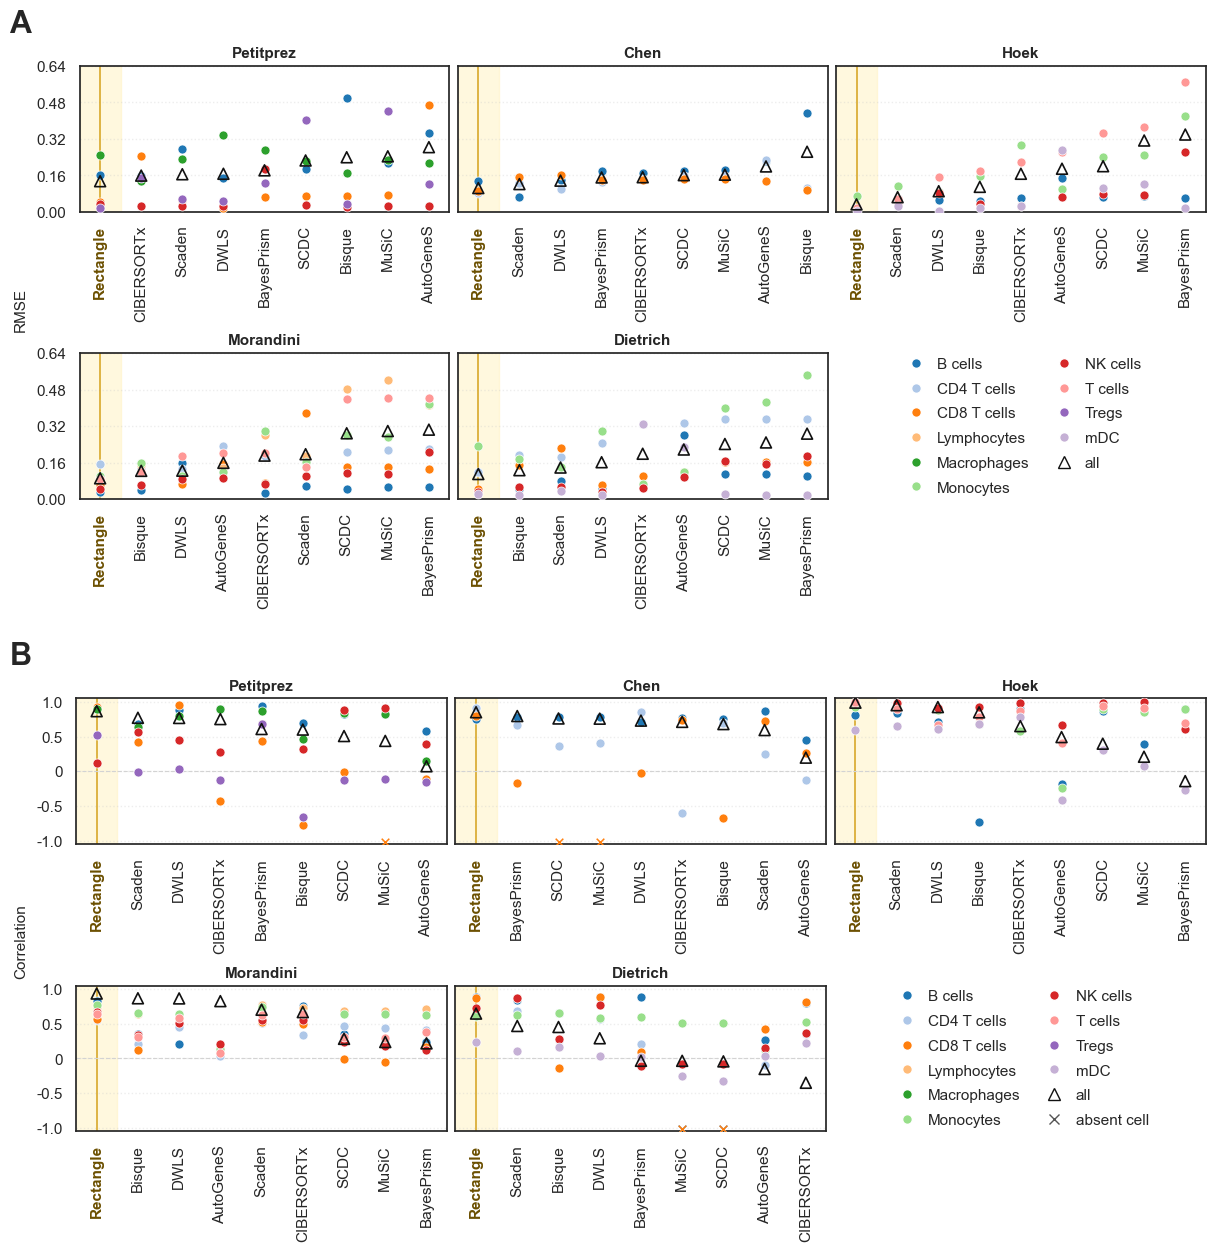

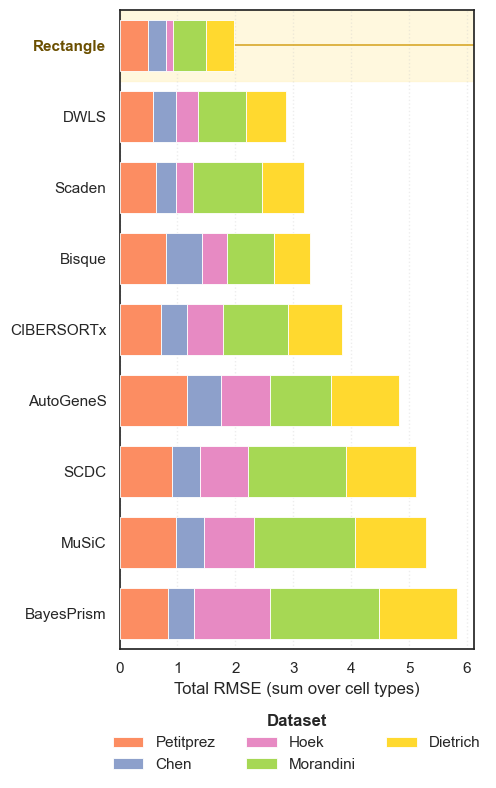

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

sns.set_style('white')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

metrics_path = '../data/fig2/cell_type_level_performance_metrics.csv'
overall_path = '../data/cor_rmse_all.csv'

# Refresh both per-cell and pooled metrics from the current saved predictions.
# This cell needs no deconvolution run or previous evaluation variables.
from pathlib import Path
import importlib
import figure2_metrics
importlib.reload(figure2_metrics)
metrics_root = Path(metrics_path).resolve().parents[2]
rectangle_cells, rectangle_overall = figure2_metrics.current_rectangle_metrics(metrics_root)
dietrich_cells, dietrich_overall = figure2_metrics.current_dietrich_comparator_metrics(metrics_root)
metric_columns = ['cell_type', 'method', 'bulk_ds', 'cor', 'RMSE']
saved_metrics = pd.read_csv(metrics_path)
saved_metrics = saved_metrics[
    (saved_metrics['method'].str.lower() != 'rectangle') &
    (saved_metrics['bulk_ds'].str.lower() != 'dietrich')
]
saved_metrics = pd.concat([saved_metrics, rectangle_cells, dietrich_cells], ignore_index=True)
saved_metrics.to_csv(metrics_path, index=False)
rectangle_overall.to_csv('../output/figure2_rectangle_current_overall_metrics.csv', index=False)
print('Current Rectangle scores (pooled over matched samples and cell types):')
print(rectangle_overall[['bulk_ds', 'RMSE', 'cor', 'n_samples', 'n_cell_types']].to_string(index=False))

# Keep the shared overall CSV current for other plots that read it.
saved_overall = pd.read_csv(overall_path, sep=';', dtype=str)
for result in rectangle_overall.to_dict('records'):
    mask = (
        saved_overall['Method'].str.strip().str.lower().eq('rectangle') &
        saved_overall['Set'].str.strip().str.lower().eq(result['bulk_ds'])
    )
    if not mask.any():
        saved_overall.loc[len(saved_overall), ['Method', 'Set']] = ['Rectangle', result['bulk_ds'].title()]
        mask = (
            saved_overall['Method'].str.strip().str.lower().eq('rectangle') &
            saved_overall['Set'].str.strip().str.lower().eq(result['bulk_ds'])
        )
    saved_overall.loc[mask, 'RMSE'] = format(result['RMSE'], '.15g').replace('.', ',')
    saved_overall.loc[mask, 'Cor'] = format(result['cor'], '.15g').replace('.', ',')
saved_overall.to_csv(overall_path, sep=';', index=False)

method_order = ['autogenes', 'bayesprism', 'bisque', 'cibersortx', 'dwls', 'music', 'scaden', 'scdc', 'rectangle']
rectangle_idx = method_order.index('rectangle')
# Finotello is excluded from these plots
bulk_order = ['petitprez', 'chen', 'hoek', 'morandini', 'dietrich']

method_labels = {
    'autogenes': 'AutoGeneS',
    'bayesprism': 'BayesPrism',
    'bisque': 'Bisque',
    'cibersortx': 'CIBERSORTx',
    'dwls': 'DWLS',
    'music': 'MuSiC',
    'scaden': 'Scaden',
    'scdc': 'SCDC',
    'rectangle': 'Rectangle'
}

bulk_labels = {
    'finotello': 'Finotello',
    'petitprez': 'Petitprez',
    'chen': 'Chen',
    'hoek': 'Hoek',
    'morandini': 'Morandini',
    'dietrich': 'Dietrich'
}

df_plot = pd.read_csv(metrics_path)
df_plot['method'] = df_plot['method'].str.lower()
df_plot['bulk_ds'] = df_plot['bulk_ds'].str.lower()
df_plot = df_plot[df_plot['method'].isin(method_order) & df_plot['bulk_ds'].isin(bulk_order)].copy()
morandini_method_metrics = figure2_metrics.morandini_comparator_metrics(metrics_root)
df_plot = df_plot[~((df_plot['bulk_ds'] == 'morandini') & (df_plot['method'] != 'rectangle'))].copy()
df_plot = pd.concat([df_plot, morandini_method_metrics], ignore_index=True)

overall_df = pd.read_csv(overall_path, sep=';')
overall_df.columns = [c.strip() for c in overall_df.columns]
overall_df['Cor'] = overall_df['Cor'].astype(str).str.replace(',', '.', regex=False).str.strip().astype(float)
overall_df['RMSE'] = overall_df['RMSE'].astype(str).str.replace(',', '.', regex=False).str.strip().astype(float)
overall_df['method'] = overall_df['Method'].astype(str).str.strip().str.lower()
overall_df['bulk_ds'] = overall_df['Set'].astype(str).str.strip().str.lower()
overall_df = overall_df[overall_df['method'].isin(method_order) & overall_df['bulk_ds'].isin(bulk_order)].copy()
# Replace all Rectangle summary rows together, including RMSE and correlation.
overall_df = overall_df[
    (overall_df['method'] != 'rectangle') &
    (~overall_df['bulk_ds'].isin(['morandini', 'dietrich']))
].copy()
overall_df['cell_type'] = 'all'
overall_df = overall_df[['cell_type', 'method', 'bulk_ds', 'Cor', 'RMSE']].rename(columns={'Cor': 'cor'})
morandini_overall = morandini_method_metrics[
    (morandini_method_metrics['cell_type'] == 'all') &
    (morandini_method_metrics['method'] != 'rectangle')
]
overall_df = pd.concat([
    overall_df, morandini_overall[metric_columns],
    dietrich_overall[metric_columns], rectangle_overall[metric_columns],
], ignore_index=True)
overall_df = overall_df[overall_df['bulk_ds'].isin(bulk_order)].copy()
if overall_df.duplicated(['method', 'bulk_ds']).any():
    raise ValueError('Duplicate overall scores for a method/dataset.')
expected_pairs = pd.MultiIndex.from_product([method_order, bulk_order], names=['method', 'bulk_ds'])
actual_pairs = pd.MultiIndex.from_frame(overall_df[['method', 'bulk_ds']])
missing_pairs = expected_pairs.difference(actual_pairs)
if len(missing_pairs):
    raise ValueError(f'Missing overall scores: {missing_pairs.tolist()}')
if not np.isfinite(overall_df['RMSE']).all():
    raise ValueError('Non-finite overall RMSE.')
# An overall score must agree with the per-cell errors for the same evaluation.
for result in rectangle_overall.to_dict('records'):
    rmse_values = rectangle_cells.loc[
        rectangle_cells['bulk_ds'] == result['bulk_ds'], 'RMSE'
    ].to_numpy()
    if not np.isclose(result['RMSE'], np.sqrt(np.mean(rmse_values ** 2))):
        raise ValueError(f'Inconsistent Rectangle metrics: {result["bulk_ds"]}')

df_plot = df_plot[df_plot['cell_type'] != 'all'].copy()
df_plot = pd.concat([df_plot, overall_df], ignore_index=True)
if df_plot.duplicated(['cell_type', 'method', 'bulk_ds']).any():
    raise ValueError('Duplicate per-cell or overall metric rows.')
df_plot['cell_type'] = df_plot['cell_type'].replace({
    'T cells CD8': 'CD8 T cells',
    'T cells CD4 conv': 'CD4 T cells',
})

cell_type_order = sorted([ct for ct in df_plot['cell_type'].dropna().unique() if ct != 'all']) + ['all']
palette = dict(zip(cell_type_order, sns.color_palette('tab20', n_colors=len(cell_type_order))))
if 'all' in palette:
    palette['all'] = '#111111'

# RMSE (A) and correlation (B) panels combined in one figure
plot_specs = [
    ('RMSE', 'RMSE', 'A'),
    ('cor', 'Correlation', 'B'),
]
combined_out_path = '../figures/fig_suppl1_celltype_method_rmse_correlation'

n_cols = 3
n_rows = int(np.ceil(len(bulk_order) / n_cols))
fig = plt.figure(figsize=(4.0 * n_cols, 3.1 * n_rows * len(plot_specs)), facecolor='white', layout='constrained')
subfigs = fig.subfigures(len(plot_specs), 1, hspace=0.04)

for subfig, (metric_col, y_label, panel_letter) in zip(subfigs, plot_specs):
    ascending = metric_col == 'RMSE'

    subfig.set_facecolor('white')
    axes = subfig.subplots(n_rows, n_cols, sharey=True)
    axes = np.array(axes).reshape(-1)

    metric_max = float(df_plot[metric_col].max(skipna=True))
    if metric_col == 'cor':
        y_lim = (-1.05, 1.05)
        y_ticks = list(np.linspace(-1, 1, 5))
        y_tick_labels = [f'{v:.1f}' if v != 0 else '0' for v in y_ticks]
    else:
        y_lim = (0, max(metric_max * 1.12, 0.1))
        y_ticks = list(np.linspace(0, y_lim[1], 5))
        y_tick_labels = [f'{v:.2f}' for v in y_ticks]

    for ax, bulk in zip(axes, bulk_order):
        ax.set_facecolor('white')
        sub = df_plot[df_plot['bulk_ds'] == bulk]
        all_metric = (
            sub[sub['cell_type'] == 'all']
            .set_index('method')[metric_col]
            .reindex(method_order)
        )
        plot_method_order = all_metric.sort_values(ascending=ascending).index.tolist()
        plot_rectangle_idx = plot_method_order.index('rectangle') if 'rectangle' in plot_method_order else None
        if plot_rectangle_idx is not None:
            ax.axvspan(plot_rectangle_idx - 0.5, plot_rectangle_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
            ax.axvline(plot_rectangle_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

        for ct in cell_type_order:
            d_ct = sub[sub['cell_type'] == ct]
            if d_ct.empty:
                continue
            x_vals = np.array([plot_method_order.index(m) for m in d_ct['method']], dtype=int)
            y_vals = d_ct[metric_col]
            marker_style = '^' if ct == 'all' else 'o'
            marker_size = 62 if ct == 'all' else 42
            face_color = 'none' if ct == 'all' else palette[ct]
            edge_color = '#111111' if ct == 'all' else 'white'
            line_width = 1.2 if ct == 'all' else 0.5

            if metric_col == 'cor':
                valid_mask = y_vals.notna().to_numpy()
                if valid_mask.any():
                    ax.scatter(
                        x_vals[valid_mask],
                        y_vals.to_numpy()[valid_mask],
                        s=marker_size,
                        marker=marker_style,
                        facecolors=face_color,
                        edgecolors=edge_color,
                        linewidths=line_width,
                        zorder=3
                    )
                if (~valid_mask).any():
                    nan_y = y_lim[0] + 0.03
                    nan_marker_color = '#111111' if ct == 'all' else palette[ct]
                    ax.scatter(
                        x_vals[~valid_mask],
                        np.full((~valid_mask).sum(), nan_y, dtype=float),
                        s=30,
                        marker='x',
                        color=nan_marker_color,
                        linewidths=1.1,
                        zorder=4,
                    )
            else:
                ax.scatter(
                    x_vals,
                    y_vals,
                    s=marker_size,
                    marker=marker_style,
                    facecolors=face_color,
                    edgecolors=edge_color,
                    linewidths=line_width,
                    zorder=3
                )

        if metric_col == 'cor':
            ax.axhline(0, linestyle='--', color='lightgrey', linewidth=0.8, zorder=1)
        ax.set_title(bulk_labels[bulk], fontsize=11, weight='bold')
        ax.set_xlim(-0.5, len(plot_method_order) - 0.5)
        ax.set_ylim(*y_lim)
        ax.set_xticks(range(len(plot_method_order)))
        ax.set_xticklabels([method_labels[m] for m in plot_method_order], rotation=90)
        for lbl, m in zip(ax.get_xticklabels(), plot_method_order):
            if m == 'rectangle':
                lbl.set_fontweight('bold')
                lbl.set_color('#6b4f00')
        ax.grid(axis='y', linestyle=':', alpha=0.35)

    for ax in axes[:len(bulk_order)]:
        ax.set_yticks(y_ticks)
        ax.set_yticklabels(y_tick_labels)
    for ax in axes[len(bulk_order):]:
        ax.axis('off')

    subfig.supylabel(y_label, fontsize=11)
    # As a suptitle, constrained layout reserves space for the letter above the panels
    subfig.suptitle(panel_letter, x=0.0, ha='left', fontsize=22, fontweight='bold')
    legend_handles = [
        Line2D([0], [0], marker='^', linestyle='None', markerfacecolor='none', markeredgecolor='#111111', markersize=8, label='all') if ct == 'all'
        else Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=palette[ct], markeredgecolor='white', markersize=7, label=ct)
        for ct in cell_type_order
    ]
    if metric_col == 'cor':
        legend_handles.append(
            Line2D([0], [0], marker='x', linestyle='None', color='#555555', markersize=7, label='absent cell')
        )
    spare_axes = axes[len(bulk_order):]
    if len(spare_axes):
        # Put the legend in the empty grid slot next to the last panel
        spare_axes[0].legend(handles=legend_handles, loc='center', ncol=2, frameon=False,
                             handletextpad=0.4, columnspacing=1.2, labelspacing=0.7)
    else:
        subfig.legend(handles=legend_handles, loc='outside right center', frameon=False)

for ext in ('pdf', 'png'):
    fig.savefig(f'{combined_out_path}.{ext}', facecolor='white', bbox_inches='tight', dpi=300)
plt.show()

# Stacked barplot: total RMSE per method, stacked by dataset (exclude 'all')
rmse_stack_df = (
    df_plot[df_plot['cell_type'] != 'all']
    .groupby(['method', 'bulk_ds'], as_index=False)['RMSE']
    .sum()
)

rmse_stack_pivot = (
    rmse_stack_df.pivot(index='method', columns='bulk_ds', values='RMSE')
    .reindex(index=method_order, columns=bulk_order)
    .fillna(0.0)
)
rmse_stack_order = rmse_stack_pivot.sum(axis=1).sort_values(ascending=True).index.tolist()
rmse_stack_pivot = rmse_stack_pivot.reindex(index=rmse_stack_order)
rectangle_stack_idx = rmse_stack_order.index('rectangle') if 'rectangle' in rmse_stack_order else None

# Keep each dataset's colour as it was when Finotello was included
palette_datasets = ['finotello'] + bulk_order
dataset_palette = dict(zip(palette_datasets, sns.color_palette('Set2', n_colors=len(palette_datasets))))

fig, ax = plt.subplots(figsize=(5, 9.2), facecolor='white')
ax.set_facecolor('white')
if rectangle_stack_idx is not None:
    ax.axhspan(rectangle_stack_idx - 0.5, rectangle_stack_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
    ax.axhline(rectangle_stack_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)

left = np.zeros(len(rmse_stack_order), dtype=float)
y = np.arange(len(rmse_stack_order))
for bulk in bulk_order:
    vals = rmse_stack_pivot[bulk].to_numpy(dtype=float)
    ax.barh(
        y,
        vals,
        left=left,
        height=0.72,
        color=dataset_palette[bulk],
        edgecolor='white',
        linewidth=0.6,
        label=bulk_labels.get(bulk, bulk.title()),
        zorder=3,
    )
    left += vals

ax.set_ylim(-0.5, len(rmse_stack_order) - 0.5)
ax.set_yticks(y)
ax.set_yticklabels([method_labels[m] for m in rmse_stack_order])
ax.invert_yaxis()
for lbl, m in zip(ax.get_yticklabels(), rmse_stack_order):
    if m == 'rectangle':
        lbl.set_fontweight('bold')
        lbl.set_color('#6b4f00')

ax.set_xlabel('Total RMSE (sum over cell types)')
ax.grid(axis='x', linestyle=':', alpha=0.35)
legend_ncol = int(np.ceil(len(bulk_order) / 2))
legend = ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=legend_ncol, frameon=False, title='Dataset')
legend.get_title().set_fontweight('bold')
plt.tight_layout(rect=[0.0, 0.12, 1.0, 1.0])
plt.savefig('../figures/fig2a_method_dataset_rmse_stacked.pdf', facecolor='white', bbox_inches='tight')
plt.show()

## Scaling

In [2]:
# you can find a zipped version of the file under: https://figshare.com/account/articles/32521659
adata_hao = anndata.read_h5ad('../data/fig2/hao_adata.h5ad')
adata_hao.obs.value_counts()
bulks_fino = pd.read_csv("../data/fig2/finotello/bulks_finotello_tpm.csv", index_col=0)

In [3]:
# for 1000, 5000,10000,50000, 100000, all cells make subsets with the same percentage of each cell type
def _sample(adata: AnnData, size: int, run=0) -> AnnData:
    np.random.seed(run)
    annotations = adata.obs['cell_type']
    annotation_counts = annotations.value_counts()
    selected_cells = []
    # makes sure that each cell type is represented  but keep the proportions
    for annotation in annotation_counts.index:
        cells = annotations[annotations == annotation].index
        n_select = max(1, int(size * (len(cells) / len(annotations))))
        cells = np.random.choice(cells, min(n_select, len(cells)), replace=False)
        selected_cells.extend(cells)
    # if we have less cells than size, we randomly add cells
    while len(selected_cells) < size:
        cell = np.random.choice(annotations.index, 1, replace=False)[0]
        if cell not in selected_cells:
            selected_cells.append(cell)
    return adata[selected_cells, :]
# python
import psutil, threading, time, gc

MB = 1024 * 1024

class PeakRSS:
    def __init__(self, include_children=True, interval=0.01):
        self.proc = psutil.Process()
        self.include_children = include_children
        self.interval = interval
        self.max_rss = 0
        self._stop = threading.Event()
        self._t = None

    def _rss_now(self):
        rss = 0
        try:
            rss += self.proc.memory_info().rss
        except psutil.Error:
            pass
        if self.include_children:
            for c in self.proc.children(recursive=True):
                try:
                    rss += c.memory_info().rss
                except psutil.Error:
                    pass
        return rss

    def start(self):
        self.max_rss = 0
        self._stop.clear()
        self._t = threading.Thread(target=self._run, daemon=True)
        self._t.start()

    def _run(self):
        while not self._stop.is_set():
            self.max_rss = max(self.max_rss, self._rss_now())
            time.sleep(self.interval)

    def stop(self):
        self._stop.set()
        if self._t:
            self._t.join()


In [4]:
# Each run starts a fresh Python process, so memory freed by earlier runs can't be reused and
# hide the real cost. Memory is the absolute peak RSS (incl. child processes) in MiB, like the
# other methods' Peak_Mem_MiB. The signature-building and deconvolution phases are measured
# separately (time_signature, time_deconvolution, memory_*). Workers import Rectangle from
# local_src (first cell), not the installed rectanglepy.
# Writes rectangle_{runtime,memory}.csv and their summaries (~35 min).
import subprocess
import sys

def run_rectangle_benchmark(*args):
    command = [sys.executable, '-u', '../scripts/benchmark_rectangle.py', *args, '--rectangle-src', str(local_src)]
    # Stream the script's progress into the notebook
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as proc:
        for line in proc.stdout:
            print(line, end='')
    if proc.returncode:
        raise subprocess.CalledProcessError(proc.returncode, proc.args)

run_rectangle_benchmark('cells')

n_cells=   1000, run 1: 32.9 s (signature 30.3 s, deconvolution 2.6 s), peak 2529 MiB (baseline 259 MiB)
n_cells=   1000, run 2: 32.8 s (signature 30.2 s, deconvolution 2.6 s), peak 2534 MiB (baseline 259 MiB)
n_cells=   1000, run 3: 31.7 s (signature 29.1 s, deconvolution 2.6 s), peak 2524 MiB (baseline 257 MiB)
n_cells=   5000, run 1: 29.3 s (signature 26.1 s, deconvolution 3.1 s), peak 3002 MiB (baseline 354 MiB)
n_cells=   5000, run 2: 29.5 s (signature 26.3 s, deconvolution 3.2 s), peak 3016 MiB (baseline 354 MiB)
n_cells=   5000, run 3: 29.5 s (signature 26.3 s, deconvolution 3.1 s), peak 3019 MiB (baseline 358 MiB)
n_cells=  10000, run 1: 29.4 s (signature 25.9 s, deconvolution 3.4 s), peak 3501 MiB (baseline 482 MiB)
n_cells=  10000, run 2: 29.9 s (signature 26.5 s, deconvolution 3.3 s), peak 3502 MiB (baseline 481 MiB)
n_cells=  10000, run 3: 29.7 s (signature 26.4 s, deconvolution 3.2 s), peak 3276 MiB (baseline 481 MiB)
n_cells=  20000, run 1: 29.7 s (signature 26.3 s, decon

In [6]:
runtime_df = pd.read_csv('../data/fig2/runtimes/rectangle_runtime.csv')
memory_df = pd.read_csv('../data/fig2/runtimes/rectangle_memory.csv')

def summarize_runs(df, size_col, metric):
    # mean and sd per size of the total (e.g. time) and each measured phase (time_signature, ...)
    value_cols = [c for c in df.columns if c == metric or c.startswith(f'{metric}_')]
    summary = df.groupby(size_col)[value_cols].agg(['mean', 'std'])
    summary.columns = [f"{col}_{'sd' if stat == 'std' else stat}" for col, stat in summary.columns]
    return summary.reset_index()

# compute and save summary (mean and std)
runtime_summary = summarize_runs(runtime_df, 'n_cells', 'time')
memory_summary = summarize_runs(memory_df, 'n_cells', 'memory')

runtime_summary.to_csv('../data/fig2/runtimes/rectangle_runtime_summary.csv', index=False)
memory_summary.to_csv('../data/fig2/runtimes/rectangle_memory_summary.csv', index=False)

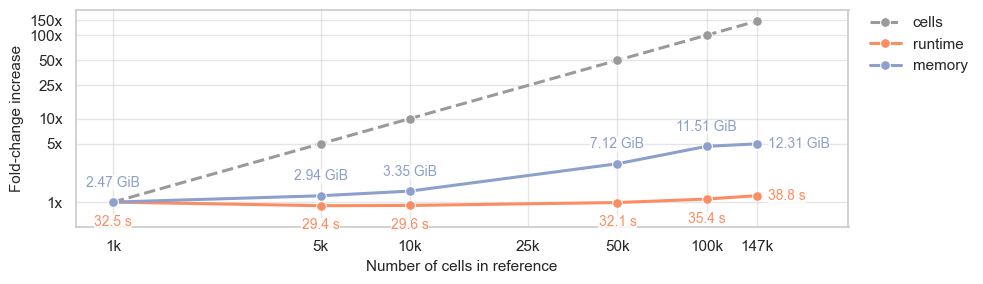

In [7]:
import seaborn as sns
# memory_summary is in MiB; convert a copy to GiB so re-running this cell doesn't divide twice
memory_summary_gib = memory_summary.assign(
    memory_mean=memory_summary['memory_mean'] / 1024,
    memory_sd=memory_summary['memory_sd'] / 1024,
)

df_combined = pd.merge(runtime_summary, memory_summary_gib, on='n_cells')
# Fold-increase plot: cells, runtime, and memory
sns.set_theme(style="whitegrid")

df = df_combined.sort_values("n_cells").reset_index(drop=True).copy()
base = df.iloc[0]

# remove those points they crowd the plot
df = df[df['n_cells']!= 90000]
df = df[df['n_cells']!= 80000]
df = df[df['n_cells']!= 35000]

df = df[df['n_cells']!= 20000]
df["cells_x"] = df["n_cells"] / base["n_cells"]
df["time_x"] = df["time_mean"] / base["time_mean"]
df["memory_x"] = df["memory_mean"] / base["memory_mean"]

plot_df = df.melt(
    id_vars="n_cells",
    value_vars=["cells_x", "time_x", "memory_x"],
    var_name="metric",
    value_name="fold_increase",
)

label_map = {
    "cells_x": "cells",
    "time_x": "runtime",
    "memory_x": "memory",
}
plot_df["metric"] = plot_df["metric"].map(label_map)

metric_styles = {
    "cells": {"color": "#9A9A9A", "linestyle": "--"},
    "runtime": {"color": "#FC8D62", "linestyle": "-"},
    "memory": {"color": "#8DA0CB", "linestyle": "-"},
}

plt.figure(figsize=(10, 3))
ax = plt.gca()
for metric, style in metric_styles.items():
    metric_df = plot_df[plot_df["metric"] == metric]
    sns.lineplot(
        data=metric_df,
        x="n_cells",
        y="fold_increase",
        marker="o",
        linewidth=2.2,
        markersize=7,
        label=metric,
        ax=ax,
        **style,
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Number of cells in reference", fontsize=11)
ax.set_ylabel(f"Fold-change increase", fontsize=11)

# Short labels so the two close ticks at 100k and all cells (147,391) don't collide
x_ticks = [1000, 5000, 10000, 25000, 50000, 100000, int(df["n_cells"].max())]
ax.set_xticks(x_ticks)
ax.set_xticklabels([f"{round(x / 1000)}k" for x in x_ticks])
ax.minorticks_off()
ax.set_yticks([1, 5, 10, 25, 50, 100, 150])
ax.set_yticklabels(["1x", "5x", "10x", "25x", "50x", "100x", "150x"])

# Memory stays above runtime after the first point, so label memory above its line and runtime below
# The last two points are close on the log axis, so the last point is labelled to its right
label_bbox = {"facecolor": "white", "edgecolor": "none", "alpha": 0.8, "pad": 0.2}
last_n_cells = df["n_cells"].max()
for _, row in df.iterrows():
    is_last = row["n_cells"] == last_n_cells
    ax.annotate(
        f"{row['time_mean']:.1f} s",
        (row["n_cells"], row["time_x"]),
        xytext=(8, 0) if is_last else (0, -9), textcoords="offset points",
        fontsize=10, color="#FC8D62", ha="left" if is_last else "center",
        va="center" if is_last else "top", bbox=label_bbox,
    )
    ax.annotate(
        f"{row['memory_mean']:.2f} GiB",
        (row["n_cells"], row["memory_x"]),
        xytext=(8, 0) if is_last else (0, 9), textcoords="offset points",
        fontsize=10, color="#8DA0CB", ha="left" if is_last else "center",
        va="center" if is_last else "bottom", bbox=label_bbox,
    )
# Leave room below the runtime line and right of the last point for the labels
ax.set_ylim(0.5, 200)
ax.set_xlim(750, 300000)

ax.legend(title="", loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, frameon=False)
plt.tight_layout()
plt.savefig("../figures/fig2d_rectangle_benchmark_fold_increase.pdf")
plt.show()


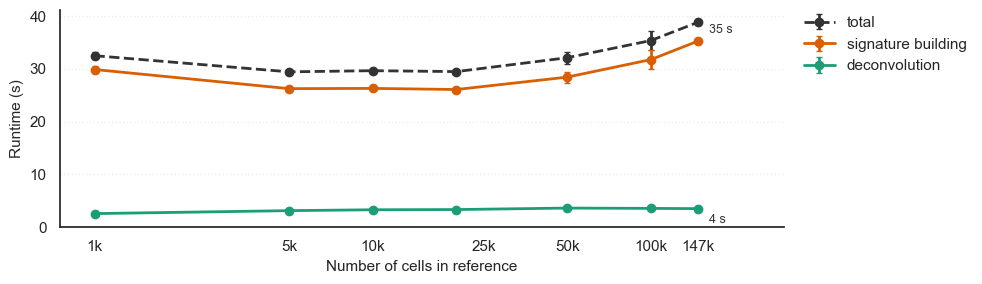

,n_cells,time_mean,time_sd,time_signature_mean,time_signature_sd,time_deconvolution_mean,time_deconvolution_sd
0,1000,32.5,0.7,29.9,0.7,2.6,0.0
1,5000,29.4,0.1,26.2,0.1,3.1,0.0
2,10000,29.6,0.2,26.3,0.3,3.3,0.1
3,20000,29.5,0.2,26.1,0.2,3.4,0.0
4,50000,32.1,1.1,28.4,1.0,3.6,0.2
5,100000,35.4,1.8,31.7,1.8,3.6,0.0
6,147391,38.8,0.5,35.2,0.5,3.5,0.0


In [8]:
# Runtime of the two Rectangle phases against the reference size (same runs as the fold-change plot).
# Signature building depends on the reference; deconvolution on the bulks (here always the 9 Finotello samples).
import numpy as np
from matplotlib.ticker import FuncFormatter

phase_styles = {
    'total': {'label': 'total', 'color': '#333333', 'linestyle': '--'},
    'signature': {'label': 'signature building', 'color': '#D95F02', 'linestyle': '-'},
    'deconvolution': {'label': 'deconvolution', 'color': '#1B9E77', 'linestyle': '-'},
}

def plot_phases(ax, summary, size_col, metric='time', scale=1.0, unit='s', include_total=True):
    """Mean +- sd per phase; the last point of each phase is labelled with its value."""
    phases = [p for p in phase_styles if include_total or p != 'total']
    missing = [f'{metric}_{p}_mean' for p in phases if p != 'total' and f'{metric}_{p}_mean' not in summary]
    if missing:
        raise KeyError(f'No phase measurements {missing}; rerun the benchmark first.')
    summary = summary.sort_values(size_col)
    for phase in phases:
        key = metric if phase == 'total' else f'{metric}_{phase}'
        style = phase_styles[phase]
        y = summary[f'{key}_mean'] / scale
        ax.errorbar(summary[size_col], y, yerr=summary[f'{key}_sd'] / scale, marker='o', markersize=6,
                    linewidth=2, capsize=2, color=style['color'], linestyle=style['linestyle'], label=style['label'])
        if phase != 'total':
            ax.annotate(f'{y.iloc[-1]:.1f} {unit}' if scale != 1 else f'{y.iloc[-1]:.0f} {unit}',
                        (summary[size_col].iloc[-1], y.iloc[-1]), textcoords='offset points',
                        # signature above, deconvolution below, in case the two end close together
                        xytext=(8, 4) if phase == 'signature' else (8, -4),
                        va='bottom' if phase == 'signature' else 'top', fontsize=9, color='#333333')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', linestyle=':', alpha=0.35)
    ax.grid(axis='x', visible=False)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

sns.set_style('white')
fig, ax = plt.subplots(figsize=(10, 3))
plot_phases(ax, runtime_summary, 'n_cells')
ax.set_xscale('log')
ax.set_xticks([1000, 5000, 10000, 25000, 50000, 100000, int(runtime_summary['n_cells'].max())])
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{round(x / 1000)}k'))
ax.minorticks_off()
ax.set_xlim(750, 300000)
ax.set_xlabel('Number of cells in reference', fontsize=11)
ax.set_ylabel('Runtime (s)', fontsize=11)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, frameon=False)
plt.tight_layout()
plt.savefig('../figures/fig_suppl_rectangle_runtime_phases_cells.pdf')
plt.show()
runtime_summary.round(1)

## Scaling with the number of bulk samples
The reference is fixed and the bulks are random subsets (one subset per size, used for all 3 runs; all samples are always included). Signature building and deconvolution are measured separately.
- **Wu**: Wu 2021 BRCA with the 22 cell types of `figure_4.ipynb` (88,309 cells) + TCGA BRCA (1,091 samples, ribosomal genes removed).
- **Morandini**: Hao_sub signature + Morandini (159 samples).

Both are run so we can decide which one to show.

In [10]:
# Wu (22 cell types) + TCGA BRCA; writes rectangle_bulks_wu_{runtime,memory}*.csv (~2 h)
run_rectangle_benchmark('bulks', '--dataset', 'wu')

wu: 1091 bulk samples, sizes [10, 50, 250, 500, 1091]
n_bulks=     10, run 1: 64.8 s (signature 57.7 s, deconvolution 7.1 s), peak 7293 MiB (baseline 1945 MiB)
n_bulks=     10, run 2: 64.6 s (signature 57.4 s, deconvolution 7.2 s), peak 8000 MiB (baseline 1943 MiB)
n_bulks=     10, run 3: 63.2 s (signature 56.2 s, deconvolution 7.0 s), peak 7853 MiB (baseline 1945 MiB)
n_bulks=     50, run 1: 75.4 s (signature 56.1 s, deconvolution 19.2 s), peak 8121 MiB (baseline 1950 MiB)
n_bulks=     50, run 2: 75.3 s (signature 56.1 s, deconvolution 19.2 s), peak 7947 MiB (baseline 1953 MiB)
n_bulks=     50, run 3: 75.4 s (signature 56.2 s, deconvolution 19.2 s), peak 7853 MiB (baseline 1950 MiB)
n_bulks=    250, run 1: 140.1 s (signature 57.3 s, deconvolution 82.8 s), peak 7945 MiB (baseline 1984 MiB)
n_bulks=    250, run 2: 139.0 s (signature 56.4 s, deconvolution 82.6 s), peak 9034 MiB (baseline 1981 MiB)
n_bulks=    250, run 3: 137.2 s (signature 55.9 s, deconvolution 81.3 s), peak 8062 MiB (ba

In [11]:
# Hao_sub + Morandini; writes rectangle_bulks_morandini_{runtime,memory}*.csv (~30 min)
run_rectangle_benchmark('bulks', '--dataset', 'morandini')

morandini: 159 bulk samples, sizes [10, 25, 50, 100, 159]
n_bulks=     10, run 1: 46.2 s (signature 42.3 s, deconvolution 3.8 s), peak 8822 MiB (baseline 2931 MiB)
n_bulks=     10, run 2: 45.3 s (signature 41.1 s, deconvolution 4.2 s), peak 8893 MiB (baseline 2932 MiB)
n_bulks=     10, run 3: 46.3 s (signature 42.0 s, deconvolution 4.2 s), peak 8688 MiB (baseline 2930 MiB)
n_bulks=     25, run 1: 48.5 s (signature 42.8 s, deconvolution 5.7 s), peak 8824 MiB (baseline 2935 MiB)
n_bulks=     25, run 2: 46.1 s (signature 40.8 s, deconvolution 5.2 s), peak 8895 MiB (baseline 2936 MiB)
n_bulks=     25, run 3: 49.3 s (signature 43.9 s, deconvolution 5.4 s), peak 8912 MiB (baseline 2937 MiB)
n_bulks=     50, run 1: 49.6 s (signature 42.6 s, deconvolution 6.9 s), peak 8946 MiB (baseline 2943 MiB)
n_bulks=     50, run 2: 50.7 s (signature 43.7 s, deconvolution 7.0 s), peak 8927 MiB (baseline 2943 MiB)
n_bulks=     50, run 3: 51.2 s (signature 44.3 s, deconvolution 6.9 s), peak 8936 MiB (baselin

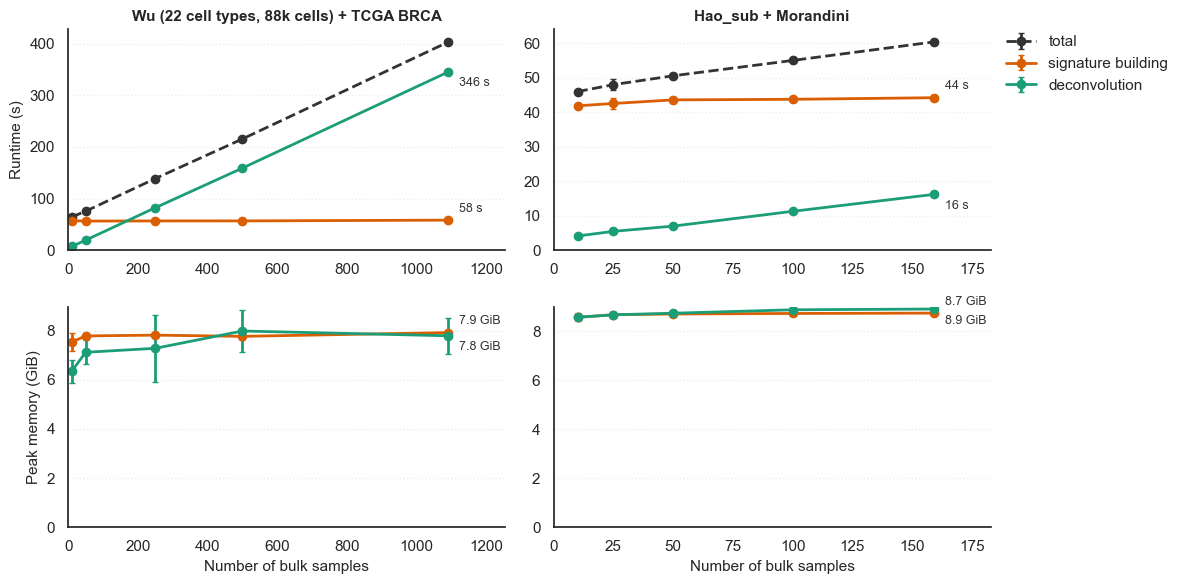

Wu (22 cell types, 88k cells) + TCGA BRCA


,n_bulks,time_mean,time_sd,time_signature_mean,time_signature_sd,time_deconvolution_mean,time_deconvolution_sd,memory_mean,memory_sd,memory_signature_mean,memory_signature_sd,memory_deconvolution_mean,memory_deconvolution_sd
0,10,64.2,0.8,57.1,0.7,7.1,0.1,7715.2,372.7,7715.2,372.7,6500.3,480.7
1,50,75.4,0.0,56.2,0.1,19.2,0.0,7973.5,136.1,7973.5,136.1,7291.0,505.1
2,250,138.8,1.5,56.5,0.7,82.2,0.8,8347.0,597.8,8005.7,58.5,7457.4,1385.5
3,500,215.7,0.6,56.6,1.1,159.1,0.6,8438.0,433.9,7955.6,134.4,8177.8,868.7
4,1091,403.8,4.5,58.0,0.6,345.7,3.9,8334.3,412.6,8112.0,76.0,7978.6,752.1


Hao_sub + Morandini


,n_bulks,time_mean,time_sd,time_signature_mean,time_signature_sd,time_deconvolution_mean,time_deconvolution_sd,memory_mean,memory_sd,memory_signature_mean,memory_signature_sd,memory_deconvolution_mean,memory_deconvolution_sd
0,10,45.9,0.5,41.8,0.6,4.1,0.2,8800.9,104.1,8764.2,165.3,8767.6,84.2
1,25,47.9,1.7,42.5,1.6,5.4,0.2,8877.1,46.8,8874.8,50.8,8870.7,40.4
2,50,50.5,0.8,43.5,0.8,6.9,0.0,8936.6,9.5,8904.0,0.8,8936.6,9.5
3,100,55.0,0.7,43.7,0.7,11.2,0.1,9080.0,15.8,8926.7,6.8,9080.0,15.8
4,159,60.3,0.8,44.2,0.9,16.1,0.1,9111.3,75.3,8941.1,2.5,9111.3,75.3


In [13]:
# Runtime (top) and peak memory (bottom) per phase against the number of bulk samples.
# Peak memory is the highest RSS during each phase, so the phases don't add up.
bulk_datasets = {
    'wu': 'Wu (22 cell types, 88k cells) + TCGA BRCA',
    'morandini': 'Hao_sub + Morandini',
}
bulk_summaries = {}
for dataset in bulk_datasets:
    bulk_runtime_df = pd.read_csv(f'../data/fig2/runtimes/rectangle_bulks_{dataset}_runtime.csv')
    bulk_memory_df = pd.read_csv(f'../data/fig2/runtimes/rectangle_bulks_{dataset}_memory.csv')
    bulk_summaries[dataset] = summarize_runs(bulk_runtime_df, 'n_bulks', 'time').merge(
        summarize_runs(bulk_memory_df, 'n_bulks', 'memory'), on='n_bulks')

sns.set_style('white')
fig, axes = plt.subplots(2, len(bulk_datasets), figsize=(6 * len(bulk_datasets), 6), squeeze=False)
for col, (dataset, title) in enumerate(bulk_datasets.items()):
    summary = bulk_summaries[dataset]
    ax_rt, ax_mem = axes[:, col]
    plot_phases(ax_rt, summary, 'n_bulks')
    ax_rt.set_title(title, fontsize=11, weight='bold')
    plot_phases(ax_mem, summary, 'n_bulks', metric='memory', scale=1024, unit='GiB', include_total=False)
    for ax in (ax_rt, ax_mem):
        ax.set_xlim(0, summary['n_bulks'].max() * 1.15)
    ax_mem.set_xlabel('Number of bulk samples', fontsize=11)
axes[0, 0].set_ylabel('Runtime (s)', fontsize=11)
axes[1, 0].set_ylabel('Peak memory (GiB)', fontsize=11)
axes[0, -1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0, frameon=False)
plt.tight_layout()
plt.savefig('../figures/fig_suppl_rectangle_runtime_phases_bulks.pdf')
plt.show()

for dataset, title in bulk_datasets.items():
    print(title)
    display(bulk_summaries[dataset].round(1))

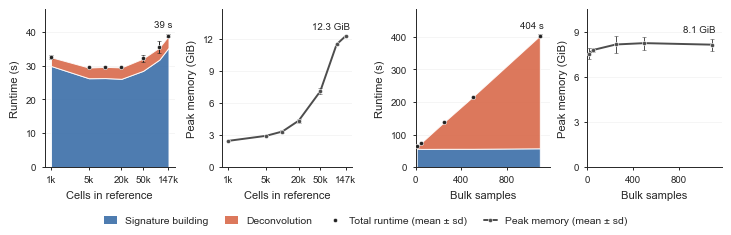

In [7]:
# Figure 2 D and E: Rectangle runtime and peak memory, split into signature building and deconvolution.
# D: reference size (Hao subsets against the 9 Finotello bulks), runtime and peak memory.
# E: number of bulk samples (Wu reference, 22 cell types, against TCGA BRCA subsets), runtime and peak memory.
# Runtime: stacked phase means, markers = total runtime (mean +- sd over the runs).
# Memory: peak RSS of the whole run (incl. child processes), mean +- sd, like Peak_Mem_MiB of the other methods.
import json
import matplotlib as mpl
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator

GIB = 1024  # memory CSVs are in MiB
runtime_dir = '../data/fig2/runtimes'

def phase_summary(runtime_path, memory_path, size_col):
    runtime = pd.read_csv(runtime_path)
    memory = pd.read_csv(memory_path)
    summary = runtime.groupby(size_col).agg(
        total=('time', 'mean'), total_sd=('time', 'std'),
        signature=('time_signature', 'mean'), deconvolution=('time_deconvolution', 'mean'),
    ).join(memory.groupby(size_col).agg(
        peak_memory=('memory', 'mean'), peak_memory_sd=('memory', 'std'),
    ) / GIB).reset_index()
    return summary

cells_sum = phase_summary(f'{runtime_dir}/rectangle_runtime.csv', f'{runtime_dir}/rectangle_memory.csv', 'n_cells')
wu_sum = phase_summary(f'{runtime_dir}/rectangle_bulks_wu_runtime.csv',
                       f'{runtime_dir}/rectangle_bulks_wu_memory.csv', 'n_bulks')

phase_colors = {'signature': '#3B6EA8', 'deconvolution': '#D9694A'}  # steel blue / terracotta, CVD-checked
phase_labels = {'signature': 'Signature building', 'deconvolution': 'Deconvolution'}
ink, memory_color = '#222222', '#4D4D4D'

style = {
    'font.size': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'axes.linewidth': 0.7, 'xtick.major.width': 0.7, 'ytick.major.width': 0.7,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'axes.edgecolor': ink,
    'pdf.fonttype': 42, 'ps.fonttype': 42,  # keep text editable in the PDF
}

def end_label(ax, x, y, text):
    # Right-aligned to the last point, so the label stays inside the panel
    ax.annotate(text, (x, y), xytext=(3, 3), textcoords='offset points',
                ha='right', va='bottom', fontsize=7, color=ink)

def draw_runtime(ax, summary, size_col):
    x = summary[size_col].to_numpy()
    ax.stackplot(x, summary['signature'], summary['deconvolution'],
                 colors=[phase_colors['signature'], phase_colors['deconvolution']],
                 edgecolor='white', linewidth=0.7, alpha=0.9, zorder=2)
    ax.errorbar(x, summary['total'], yerr=summary['total_sd'], fmt='o', markersize=3, color=ink,
                markeredgecolor='white', markeredgewidth=0.4, elinewidth=0.7, capsize=1.5, zorder=3)
    end_label(ax, x[-1], summary['total'].iloc[-1] + np.nan_to_num(summary['total_sd'].iloc[-1]),
              f"{summary['total'].iloc[-1]:.0f} s")
    ax.set_ylim(0, summary['total'].max() * 1.2)
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.set_ylabel('Runtime (s)')

def draw_memory(ax, summary, size_col):
    x = summary[size_col].to_numpy()
    ax.errorbar(x, summary['peak_memory'], yerr=summary['peak_memory_sd'], color=memory_color,
                linewidth=1.4, marker='o', markersize=3, markeredgecolor='white', markeredgewidth=0.4,
                elinewidth=0.7, capsize=1.5, zorder=3)
    last = summary.iloc[-1]
    end_label(ax, x[-1], last['peak_memory'] + np.nan_to_num(last['peak_memory_sd']),
              f"{last['peak_memory']:.1f} GiB")
    ax.set_ylim(0, (summary['peak_memory'] + summary['peak_memory_sd'].fillna(0)).max() * 1.2)
    ax.yaxis.set_major_locator(MaxNLocator(5, integer=True))
    ax.set_ylabel('Peak memory (GiB)')

def log_ticks(sizes, min_ratio=2.5):
    # Measured sizes as ticks, skipping any too close to a neighbour on the log axis; the largest is always kept
    ticks = [sizes[0]]
    for n in sizes[1:-1]:
        if n / ticks[-1] >= min_ratio and sizes[-1] / n >= min_ratio:
            ticks.append(n)
    return ticks + [sizes[-1]]

with mpl.rc_context(style):
    sns.set_style('ticks')
    fig = plt.figure(figsize=(7.2, 2.25), layout='constrained')
    # What is held fixed in each group (9 Finotello bulks; Wu reference) goes in the caption
    groups = [
        (cells_sum, 'n_cells', 'Cells in reference'),
        (wu_sum, 'n_bulks', 'Bulk samples'),
    ]
    group_axes = []
    for subfig, (summary, size_col, xlabel) in zip(fig.subfigures(1, 2, wspace=0.03), groups):
        ax_rt, ax_mem = subfig.subplots(1, 2)
        group_axes.append((ax_rt, ax_mem))
        draw_runtime(ax_rt, summary, size_col)
        draw_memory(ax_mem, summary, size_col)
        for ax in (ax_rt, ax_mem):
            ax.set_xlabel(xlabel)
            if size_col == 'n_cells':
                sizes = summary[size_col].tolist()
                ax.set_xscale('log')
                ax.set_xticks(log_ticks(sizes))
                ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1000:.0f}k'))
                ax.minorticks_off()
                ax.set_xlim(sizes[0] / 1.3, sizes[-1] * 1.3)
            else:
                ax.set_xlim(0, summary[size_col].max() * 1.08)
                ax.xaxis.set_major_locator(MaxNLocator(3, integer=True))
            ax.grid(axis='y', color='#E5E5E5', linewidth=0.5, zorder=0)
            ax.set_axisbelow(True)
            sns.despine(ax=ax)

    legend_handles = [Patch(facecolor=phase_colors[p], edgecolor='none', alpha=0.9, label=phase_labels[p])
                      for p in phase_colors]
    legend_handles.append(Line2D([0], [0], marker='o', linestyle='none', markersize=3, color=ink,
                                 markeredgecolor='white', markeredgewidth=0.4, label='Total runtime (mean ± sd)'))
    legend_handles.append(Line2D([0], [0], color=memory_color, linewidth=1.4, marker='o', markersize=3,
                                 markeredgecolor='white', markeredgewidth=0.4, label='Peak memory (mean ± sd)'))
    # Legend below, so the panel letters can sit above the two groups
    fig.legend(handles=legend_handles, loc='outside lower center', ncol=4, frameon=False,
               handlelength=1.2, columnspacing=1.6, fontsize=7.5)

    # The Figure 2 assembly letters the groups (D, E). Record where each group starts, as a fraction
    # of the saved page width, using the same bounding box savefig(bbox_inches='tight') keeps.
    pad_inches = 0.02
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    saved_bbox = fig.get_tightbbox(renderer).padded(pad_inches)
    group_x_fractions = [
        (min(ax.get_tightbbox(renderer).x0 for ax in axes_pair) / fig.dpi - saved_bbox.x0) / saved_bbox.width
        for axes_pair in group_axes
    ]
    with open('../figures/fig2d_rectangle_runtime_memory_phases_layout.json', 'w') as f:
        json.dump({'group_x_fractions': group_x_fractions}, f, indent=1)
    for ext in ('pdf', 'png'):
        fig.savefig(f'../figures/fig2d_rectangle_runtime_memory_phases.{ext}', dpi=300,
                    bbox_inches='tight', pad_inches=pad_inches, facecolor='white')
    plt.show()

In [1]:
import time
import psutil
import pandas as pd
import numpy as np
import scanpy as sc
import anndata
import autogenes as ag

# subset sizes (include full dataset size)


n_runs = 3
runtime_records = []
memory_records = []

proc = psutil.Process()

adata_hao = anndata.read_h5ad('../data/hao_adata.h5ad')
bulks_fino = pd.read_csv("../data/bulks_finotello_tpm.csv", index_col=0)
sc.pp.normalize_total(adata_hao, target_sum=1e6)
subset_sizes = [20000]
for n_cells in subset_sizes:
    # convert to cpm
    adata_hao = _sample(adata_hao, int(n_cells), run=0)
    sc.pp.normalize_total(adata_hao, target_sum=1e6)
    print(f"Benchmarking rectangle with {n_cells} cells")

    for run in range(n_runs):
        print(f"Running run {run}")
        # brief pause to stabilise measurements
        gc.collect()
        time.sleep(0.2)
        baseline_rss = PeakRSS(include_children=True)._rss_now()

        sampler = PeakRSS(include_children=True, interval=0.01)
        sampler.start()
        t0 = time.perf_counter()
        ag.init(adata_hao,celltype_key='cell_type')
        ag.optimize(ngen=500,seed=0)
        coef = ag.deconvolve(bulks_fino.T)

        t1 = time.perf_counter()
        sampler.stop()

        elapsed_s = t1 - t0
        peak_diff_mb = max(0.0, (sampler.max_rss - baseline_rss) / MB)

        runtime_records.append({"n_cells": int(n_cells), "run": run + 1, "time": elapsed_s})
        memory_records.append({"n_cells": int(n_cells), "run": run + 1, "memory": peak_diff_mb})
        print(f"Time: {elapsed_s}s")

# save raw records
runtime_df = pd.DataFrame(runtime_records)
memory_df = pd.DataFrame(memory_records)

runtime_df.to_csv('../data/fig2/runtimes/autogenes_runtime_20k.csv')
memory_df.to_csv('../data/fig2/runtimes/autogenes_memory_20k.csv')

KeyboardInterrupt: 

In [16]:
runtime_df = pd.read_csv('../data/fig2/runtimes/autogenes_runtime_20k.csv')
memory_df = pd.read_csv('../data/fig2/runtimes/autogenes_memory_20k.csv')
runtime_summary = runtime_df.groupby('n_cells')['time'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'time_mean','std':'time_sd'})
memory_summary = memory_df.groupby('n_cells')['memory'].agg(['mean', 'std']).reset_index().rename(columns={'mean':'memory_mean','std':'memory_sd'})

runtime_summary.to_csv('../data/fig2/runtimes/autogenes_runtime_summary_20k.csv', index=False)
memory_summary.to_csv('../data/fig2/runtimes/autogenes_memory_summary_20k.csv', index=False)

In [17]:
runtimes_autogenes = pd.read_csv('../data/fig2/runtimes/autogenes_runtime_summary.csv')
memory_autogenes = pd.read_csv('../data/fig2/runtimes/autogenes_memory_summary.csv')
memory_autogenes[['memory_mean']] = memory_autogenes[['memory_mean']] / 1024  # convert to GB
memory_autogenes[['memory_sd']] = memory_autogenes[['memory_sd']] / 1024
df_combined = pd.merge(runtimes_autogenes, memory_autogenes, on='n_cells')

SCDC raw memory val: 6791514954.666667
Converting SCDC memory from Words to MiB
DWLS raw memory val: 2515917355.0
Converting DWLS memory from Words to MiB


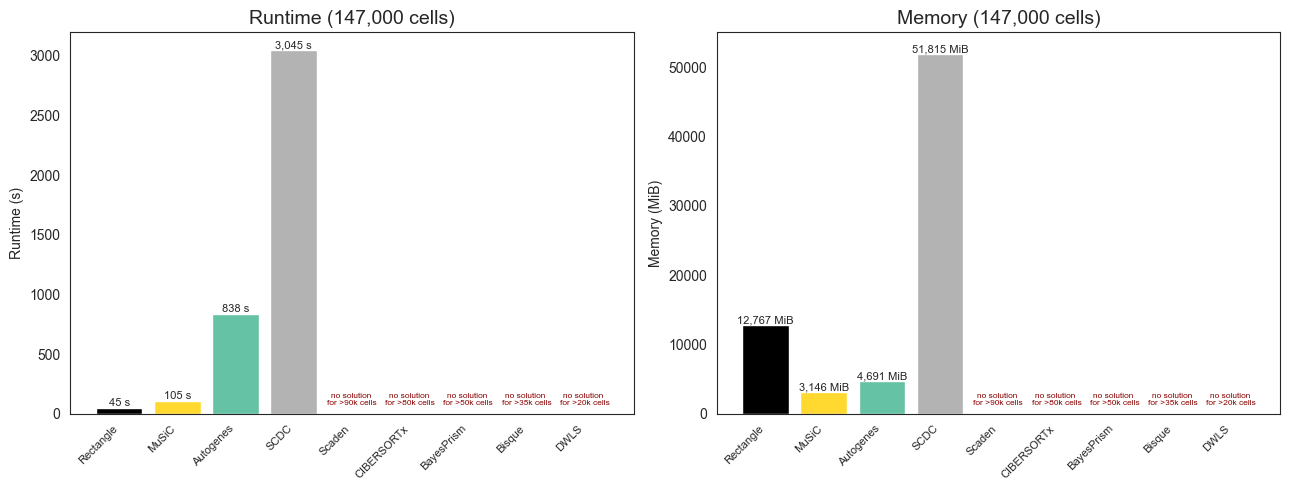

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_style("white")
# Load data
rect_mem = pd.read_csv('../data/fig2/runtimes/rectangle_memory_summary.csv')
rect_run = pd.read_csv('../data/fig2/runtimes/rectangle_runtime_summary.csv')
autogenes_mem = pd.read_csv('../data/fig2/runtimes/autogenes_memory_summary.csv')
autogenes_run = pd.read_csv('../data/fig2/runtimes/autogenes_runtime_summary.csv')
scdc = pd.read_csv('../data/fig2/runtimes/scdc.csv')
music = pd.read_csv('../data/fig2/runtimes/music.csv')
scaden = pd.read_csv('../data/fig2/runtimes/scaden.csv')
dwls = pd.read_csv('../data/fig2/runtimes/dwls_benchmark_results.csv')
bisque = pd.read_csv('../data/fig2/runtimes/bisque_benchmark_results.csv')
bayesprism_path = '../data/fig2/runtimes/bayesprism_benchmark_results.csv'
if not os.path.exists(bayesprism_path):
    bayesprism_path = '../bayesprism_benchmark_results.csv'
bayesprism = pd.read_csv(bayesprism_path)

# Rectangle data
n_cells_target = rect_mem['n_cells'].max()
rect_mem_row = rect_mem[rect_mem['n_cells'] == n_cells_target].iloc[0]
rect_run_row = rect_run[rect_run['n_cells'] == n_cells_target].iloc[0]
autogenes_mem_row = autogenes_mem[autogenes_mem['n_cells'] == n_cells_target].iloc[0]
autogenes_run_row = autogenes_run[autogenes_run['n_cells'] == n_cells_target].iloc[0]

rect_time_mean = rect_run_row['time_mean']
rect_time_sd = rect_run_row['time_sd']
rect_mem_mean = rect_mem_row['memory_mean']
rect_mem_sd = rect_mem_row['memory_sd']
autogenes_time_mean = autogenes_run_row['time_mean']
autogenes_time_sd = autogenes_run_row['time_sd']
autogenes_mem_mean = autogenes_mem_row['memory_mean']
autogenes_mem_sd = autogenes_mem_row['memory_sd']

# SCDC data
scdc_time_mean = scdc['Time_s'].mean()
scdc_time_sd = scdc['Time_s'].std()

# Music data
music_time_mean = music['Time_s'].mean()
music_time_sd = music['Time_s'].std()

music_mem_mean = music['Peak_Mem_MiB'].mean()
music_mem_sd = music['Peak_Mem_MiB'].std()

# scaden data
scaden_time_mean = scaden['Time_s'].mean()
scaden_time_sd = scaden['Time_s'].std()

scaden_mem_mean = scaden['Peak_Mem_MiB'].mean()
scaden_mem_sd = scaden['Peak_Mem_MiB'].std()

# dwls data
dwls_time_mean = dwls['Time_s'].mean()
dwls_time_sd = dwls['Time_s'].std()

dwls_mem_mean = dwls['Peak_Mem_MiB'].mean()
dwls_mem_sd = dwls['Peak_Mem_MiB'].std()

# bisque data
bisque_time_mean = bisque['Time_s'].mean()
bisque_time_sd = bisque['Time_s'].std()

bisque_mem_mean = bisque['Peak_Mem_MiB'].mean()
bisque_mem_sd = bisque['Peak_Mem_MiB'].std()

# bayesprism data
bayesprism_time_mean = bayesprism['Time_s'].mean()
bayesprism_time_sd = bayesprism['Time_s'].std()

bayesprism_mem_mean = bayesprism['Peak_Mem_MiB'].mean()
bayesprism_mem_sd = bayesprism['Peak_Mem_MiB'].std()

# Verify SCDC Memory Units
scdc_mem_raw = scdc['Peak_Mem_MiB'].mean()
print(f"SCDC raw memory val: {scdc_mem_raw}")

# If raw value > 1e6, it's definitely not MB (would be >1TB). Assuming Words.
if scdc_mem_raw > 1e6:
    print("Converting SCDC memory from Words to MiB")
    scdc_mem_mean = scdc['Peak_Mem_MiB'].mean() * 8 / (1024 * 1024)
    scdc_mem_sd = scdc['Peak_Mem_MiB'].std() * 8 / (1024 * 1024)
else:
    scdc_mem_mean = scdc['Peak_Mem_MiB'].mean()
    scdc_mem_sd = scdc['Peak_Mem_MiB'].std()

# Verify DWLS memory units
dwls_mem_raw = dwls['Peak_Mem_MiB'].mean()
print(f"DWLS raw memory val: {dwls_mem_raw}")
if dwls_mem_raw > 1e6:
    print("Converting DWLS memory from Words to MiB")
    dwls_mem_mean = dwls['Peak_Mem_MiB'].mean() * 8 / (1024 * 1024)
    dwls_mem_sd = dwls['Peak_Mem_MiB'].std() * 8 / (1024 * 1024)
else:
    dwls_mem_mean = dwls['Peak_Mem_MiB'].mean()
    dwls_mem_sd = dwls['Peak_Mem_MiB'].std()

# Create DataFrame for plotting
df_res = pd.DataFrame({
    'Method': ['Rectangle', 'SCDC' ,'Autogenes', 'MuSiC', 'Scaden', 'BayesPrism', 'Bisque', 'DWLS'],
    'Time_Mean': [rect_time_mean, scdc_time_mean, autogenes_time_mean, music_time_mean, scaden_time_mean, bayesprism_time_mean, bisque_time_mean, dwls_time_mean],
    'Time_SD': [rect_time_sd, scdc_time_sd, autogenes_time_sd, music_time_sd, scaden_time_sd, bayesprism_time_sd, bisque_time_sd, dwls_time_sd],
    'Memory_Mean': [rect_mem_mean, scdc_mem_mean, autogenes_mem_mean, music_mem_mean, scaden_mem_mean, bayesprism_mem_mean, bisque_mem_mean, dwls_mem_mean],
    'Memory_SD': [rect_mem_sd, scdc_mem_sd, autogenes_mem_sd, music_mem_sd, scaden_mem_sd, bayesprism_mem_sd, bisque_mem_sd, dwls_mem_sd],
})

runtime_map = dict(zip(df_res['Method'], df_res['Time_Mean']))
memory_map = dict(zip(df_res['Method'], df_res['Memory_Mean']))
fail_cells = {
    'DWLS': '20k',
    'Bisque': '35k',
    'BayesPrism': '50k',
    'CIBERSORTx': '80k',
    'Scaden': '90k',
}
fail_note_map = {m: f'no solution \nfor >{fail_cells[m]} cells' for m in fail_cells}

all_methods = ['Rectangle', 'SCDC', 'Autogenes', 'MuSiC', 'Scaden', 'BayesPrism', 'Bisque', 'DWLS', 'CIBERSORTx']
non_failed_methods = [m for m in all_methods if m not in fail_cells]
runtime_order_non_failed = sorted(non_failed_methods, key=lambda m: runtime_map.get(m, np.inf))
failed_order = sorted(fail_cells.keys(), key=lambda m: fail_cells[m], reverse=True)
methods_all = runtime_order_non_failed + failed_order

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
method_to_color = {
    'Rectangle': '#000000',
    'SCDC': '#B3B3B3',
    'Autogenes': '#66C2A5',
    'MuSiC': '#FFD92F',
    'Scaden': '#E5C494',
    'BayesPrism': '#FC8D62',
    'Bisque': '#8DA0CB',
    'DWLS': '#A6D854',
    'CIBERSORTx': '#E78AC3',
}
# log y axis



# Runtime Plot (vertical)
fmt_runtime = lambda x: f"{x:,.0f} s"
rt_methods = methods_all
x_rt = np.arange(len(rt_methods))
rt_raw_vals = [runtime_map.get(m, np.nan) for m in rt_methods]
forced_failed_methods = set(fail_note_map.keys())
rt_failed = [(m in forced_failed_methods) or pd.isna(v) for m, v in zip(rt_methods, rt_raw_vals)]
rt_vals = [0 if is_failed else v for v, is_failed in zip(rt_raw_vals, rt_failed)]
bars_rt = axes[0].bar(x_rt, rt_vals, color=[method_to_color[m] for m in rt_methods])
axes[0].set_ylabel('Runtime (s)')
axes[0].set_title('Runtime (147,000 cells)', fontsize=14)
axes[0].set_xticks(x_rt)
axes[0].set_xticklabels(rt_methods, rotation=45, ha='right', fontsize=8)
for bar, method, val, is_failed in zip(bars_rt, rt_methods, rt_vals, rt_failed):
    if is_failed:
        axes[0].text(bar.get_x() + bar.get_width() / 2, 0.02 * axes[0].get_ylim()[1], fail_note_map.get(method, 'no solution\nfor >XX cells'), ha='center', va='bottom', fontsize=6, color='#8B0000')
    else:
        axes[0].text(bar.get_x() + bar.get_width() / 2, val * 1.00, fmt_runtime(val), ha='center', va='bottom', fontsize=8)

# Memory Plot (vertical)
mem_methods = methods_all
x_mem = np.arange(len(mem_methods))
mem_raw_vals = [memory_map.get(m, np.nan) for m in mem_methods]
mem_failed = [(m in forced_failed_methods) or pd.isna(v) for m, v in zip(mem_methods, mem_raw_vals)]
mem_vals = [0 if is_failed else v for v, is_failed in zip(mem_raw_vals, mem_failed)]
bars_mem = axes[1].bar(x_mem, mem_vals, color=[method_to_color[m] for m in mem_methods])
axes[1].set_ylabel('Memory (MiB)')
axes[1].set_title('Memory (147,000 cells)', fontsize=14)
axes[1].set_xticks(x_mem)
axes[1].set_xticklabels(mem_methods, rotation=45, ha='right', fontsize=8)
axes[1].set_ylim(0, 55000)
fmt_memory = lambda x: f"{x:,.0f} MiB"
for bar, method, val, is_failed in zip(bars_mem, mem_methods, mem_vals, mem_failed):
    if is_failed:
        axes[1].text(bar.get_x() + bar.get_width() / 2, 0.02 * axes[1].get_ylim()[1], fail_note_map.get(method, 'no solution\nfor >XX cells'), ha='center', va='bottom', fontsize=6, color='#8B0000')
    else:
        axes[1].text(bar.get_x() + bar.get_width() / 2, val * 1.00, fmt_memory(val), ha='center', va='bottom', fontsize=8)

for ax in axes:
    ax.tick_params(axis='x', labelsize=8, labelrotation=45)

plt.tight_layout()
plt.savefig('../figures/fig_suppl_2_rectangle_comparison_fail_no_log.pdf', dpi=300)
plt.savefig('../figures/fig_suppl_2_rectangle_comparison_fail_no_log.png', dpi=300)
plt.show()





In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
sns.set_style("white")
# Load data
rect_mem = pd.read_csv('../data/fig2/runtimes/rectangle_memory_summary.csv')
rect_run = pd.read_csv('../data/fig2/runtimes/rectangle_runtime_summary.csv')
autogenes_mem = pd.read_csv('../data/fig2/runtimes/autogenes_memory_summary_20k.csv')
autogenes_run = pd.read_csv('../data/fig2/runtimes/autogenes_runtime_summary_20k.csv')
scdc = pd.read_csv('../data/fig2/runtimes/scdc_benchmark_results_20k.csv')
music = pd.read_csv('../data/fig2/runtimes/music_benchmark_results_20k.csv')
scaden = pd.read_csv('../data/fig2/runtimes/scaden_20k.csv')
dwls = pd.read_csv('../data/fig2/runtimes/dwls_benchmark_results.csv')
bisque = pd.read_csv('../data/fig2/runtimes/bisque_benchmark_results_20k.csv')
bayesprism_path = '../data/fig2/runtimes/bayesprism_benchmark_results_20k.csv'
cibersortx_runtime = pd.read_csv('../data/fig2/runtimes/cibersortx_runtime_20k.csv')
cibersortx_memory = pd.read_csv('../data/fig2/runtimes/cibersortx_memory_20k.csv')
bayesprism = pd.read_csv(bayesprism_path)

# Rectangle data
n_cells_target = rect_mem['n_cells'].max()
rect_mem_row = rect_mem[rect_mem['n_cells'] == 20000].iloc[0]
rect_run_row = rect_run[rect_run['n_cells'] == 20000].iloc[0]
autogenes_mem_row = autogenes_mem[autogenes_mem['n_cells'] == 20000].iloc[0]
autogenes_run_row = autogenes_run[autogenes_run['n_cells'] == 20000].iloc[0]

In [4]:

rect_time_mean = rect_run_row['time_mean']
rect_time_sd = rect_run_row['time_sd']
rect_mem_mean = rect_mem_row['memory_mean']
rect_mem_sd = rect_mem_row['memory_sd']
autogenes_time_mean = autogenes_run_row['time_mean']
autogenes_time_sd = autogenes_run_row['time_sd']
autogenes_mem_mean = autogenes_mem_row['memory_mean']
autogenes_mem_sd = autogenes_mem_row['memory_sd']

# SCDC data
scdc_time_mean = scdc['Time_s'].mean()
scdc_time_sd = scdc['Time_s'].std()

# Music data
music_time_mean = music['Time_s'].mean()
music_time_sd = music['Time_s'].std()

music_mem_mean = music['Peak_Mem_MiB'].mean()
music_mem_sd = music['Peak_Mem_MiB'].std()

# scaden data
scaden_time_mean = scaden['Time_s'].mean()
scaden_time_sd = scaden['Time_s'].std()

scaden_mem_mean = scaden['Peak_Mem_MiB'].mean()
scaden_mem_sd = scaden['Peak_Mem_MiB'].std()

# dwls data
dwls_time_mean = dwls['Time_s'].mean()
dwls_time_sd = dwls['Time_s'].std()

dwls_mem_mean = dwls['Peak_Mem_MiB'].mean()
dwls_mem_sd = dwls['Peak_Mem_MiB'].std()

# bisque data
bisque_time_mean = bisque['Time_s'].mean()
bisque_time_sd = bisque['Time_s'].std()

bisque_mem_mean = bisque['Peak_Mem_MiB'].mean()
bisque_mem_sd = bisque['Peak_Mem_MiB'].std()

# bayesprism data
bayesprism_time_mean = bayesprism['Time_s'].mean()
bayesprism_time_sd = bayesprism['Time_s'].std()

bayesprism_mem_mean = bayesprism['Peak_Mem_MiB'].mean()
bayesprism_mem_sd = bayesprism['Peak_Mem_MiB'].std()

cibersortx_runtime_mean = cibersortx_runtime['time'].mean()
cibersortx_memory_mean = cibersortx_memory['memory_mib'].mean()
cibersortx_runtime_std =cibersortx_runtime['time'].std()
cibersortx_memory_std = cibersortx_memory['memory_mib'].std()

# Verify SCDC Memory Units
scdc_mem_raw = scdc['Peak_Mem_MiB'].mean()
print(f"SCDC raw memory val: {scdc_mem_raw}")

# If raw value > 1e6, it's definitely not MB (would be >1TB). Assuming Words.
if scdc_mem_raw > 1e6:
    print("Converting SCDC memory from Words to MiB")
    scdc_mem_mean = scdc['Peak_Mem_MiB'].mean() * 8 / (1024 * 1024)
    scdc_mem_sd = scdc['Peak_Mem_MiB'].std() * 8 / (1024 * 1024)
else:
    scdc_mem_mean = scdc['Peak_Mem_MiB'].mean()
    scdc_mem_sd = scdc['Peak_Mem_MiB'].std()

# Verify DWLS memory units
dwls_mem_raw = dwls['Peak_Mem_MiB'].mean()
print(f"DWLS raw memory val: {dwls_mem_raw}")
if dwls_mem_raw > 1e6:
    print("Converting DWLS memory from Words to MiB")
    dwls_mem_mean = dwls['Peak_Mem_MiB'].mean() * 8 / (1024 * 1024)
    dwls_mem_sd = dwls['Peak_Mem_MiB'].std() * 8 / (1024 * 1024)
else:
    dwls_mem_mean = dwls['Peak_Mem_MiB'].mean()
    dwls_mem_sd = dwls['Peak_Mem_MiB'].std()

# Create DataFrame for plotting
df_res = pd.DataFrame({
    'Method': ['Rectangle', 'SCDC' ,'Autogenes', 'MuSiC', 'Scaden', 'BayesPrism', 'Bisque', 'DWLS', 'CIBERSORTx'],
    'Time_Mean': [rect_time_mean, scdc_time_mean, autogenes_time_mean, music_time_mean, scaden_time_mean, bayesprism_time_mean, bisque_time_mean, dwls_time_mean,cibersortx_runtime_mean],
    'Time_SD': [rect_time_sd, scdc_time_sd, autogenes_time_sd, music_time_sd, scaden_time_sd, bayesprism_time_sd, bisque_time_sd, dwls_time_sd,cibersortx_runtime_std],
    'Memory_Mean': [rect_mem_mean, scdc_mem_mean, autogenes_mem_mean, music_mem_mean, scaden_mem_mean, bayesprism_mem_mean, bisque_mem_mean, dwls_mem_mean, cibersortx_memory_mean],
    'Memory_SD': [rect_mem_sd, scdc_mem_sd, autogenes_mem_sd, music_mem_sd, scaden_mem_sd, bayesprism_mem_sd, bisque_mem_sd, dwls_mem_sd, cibersortx_memory_std],
})

SCDC raw memory val: 8044.0
DWLS raw memory val: 2515917355.0
Converting DWLS memory from Words to MiB


/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_98841/3762205444.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.0, 0.08, 1.0, 1.0])


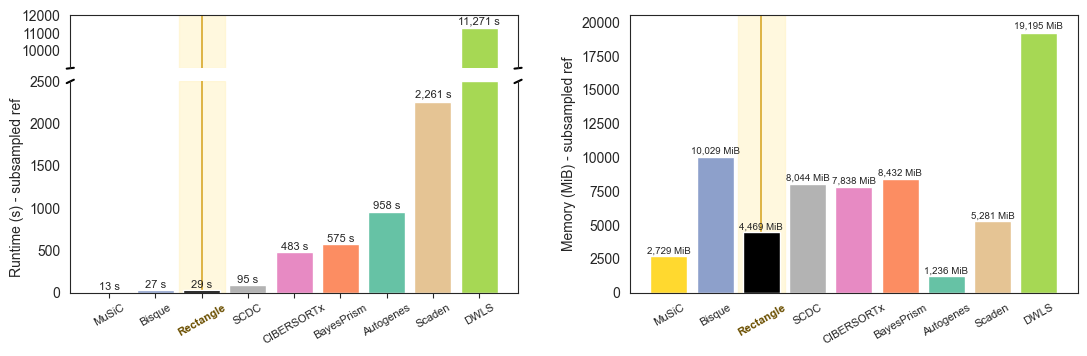

In [5]:



runtime_order = df_res.sort_values('Time_Mean', ascending=True)['Method'].tolist()
memory_order = runtime_order.copy()
runtime_map = dict(zip(df_res['Method'], df_res['Time_Mean']))
memory_map = dict(zip(df_res['Method'], df_res['Memory_Mean']))

fig = plt.figure(figsize=(13, 3.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1], height_ratios=[1, 4], wspace=0.25, hspace=0.10)
ax_rt_top = fig.add_subplot(gs[0, 0])
ax_rt_bot = fig.add_subplot(gs[1, 0], sharex=ax_rt_top)
ax_mem = fig.add_subplot(gs[:, 1])

method_to_color = {
    'Rectangle': '#000000',
    'SCDC': '#B3B3B3',
    'Autogenes': '#66C2A5',
    'MuSiC': '#FFD92F',
    'Scaden': '#E5C494',
    'BayesPrism': '#FC8D62',
    'Bisque': '#8DA0CB',
    'DWLS': '#A6D854',
    'CIBERSORTx': '#E78AC3',
}



# Runtime Plot (vertical)
fmt_runtime = lambda x: f"{x:,.0f} s"
rt_methods = runtime_order
x_rt = np.arange(len(rt_methods))
rt_vals = np.array([runtime_map[m] for m in rt_methods], dtype=float)
rt_colors = [method_to_color.get(m, '#999999') for m in rt_methods]
break_y = 2500
rt_vals_bot = np.minimum(rt_vals, break_y)
rt_vals_top = np.where(rt_vals > break_y, rt_vals, np.nan)
rectangle_rt_idx = rt_methods.index('Rectangle')
for ax in (ax_rt_top, ax_rt_bot):
    ax.axvspan(rectangle_rt_idx - 0.5, rectangle_rt_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
    ax.axvline(rectangle_rt_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)
bars_rt_top = ax_rt_top.bar(x_rt, rt_vals_top, color=rt_colors)
bars_rt_bot = ax_rt_bot.bar(x_rt, rt_vals_bot, color=rt_colors)

rt_max = float(np.nanmax(rt_vals)) if len(rt_vals) > 0 else break_y
rt_top_min = max(break_y + 1, rt_max * 0.80)
ax_rt_bot.set_ylim(0, break_y)
ax_rt_top.set_ylim(rt_top_min, rt_max * 1.04)

ax_rt_top.spines['bottom'].set_visible(False)
ax_rt_bot.spines['top'].set_visible(False)
ax_rt_top.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
ax_rt_top.set_xticks([])
ax_rt_bot.xaxis.tick_bottom()
ax_rt_top.set_yticks([t for t in ax_rt_top.get_yticks() if t >= rt_top_min])

d = .008
kwargs = dict(transform=ax_rt_top.transAxes, color='k', clip_on=False)
ax_rt_top.plot((-d, +d), (-d, +d), **kwargs)
ax_rt_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)
kwargs.update(transform=ax_rt_bot.transAxes)
ax_rt_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_rt_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

ax_rt_bot.set_ylabel('Runtime (s) - subsampled ref')
ax_rt_bot.set_xticks(x_rt)
ax_rt_bot.set_xticklabels(rt_methods)
for lbl, m in zip(ax_rt_bot.get_xticklabels(), rt_methods):
    if m == 'Rectangle':
        lbl.set_fontweight('bold')
        lbl.set_color('#6b4f00')

for bar, val in zip(bars_rt_bot, rt_vals):
    if val <= break_y:
        ax_rt_bot.text(bar.get_x() + bar.get_width() / 2, val * 1.01, fmt_runtime(val), ha='center', va='bottom', fontsize=8)
for bar, val in zip(bars_rt_top, rt_vals):
    if val > break_y:
        ax_rt_top.text(bar.get_x() + bar.get_width() / 2, val + (rt_max * 0.01), fmt_runtime(val), ha='center', va='bottom', fontsize=8)


# Memory Plot (vertical)
mem_methods = memory_order
x_mem = np.arange(len(mem_methods))
mem_vals = [memory_map[m] for m in mem_methods]
rectangle_mem_idx = mem_methods.index('Rectangle')
ax_mem.axvspan(rectangle_mem_idx - 0.5, rectangle_mem_idx + 0.5, color='#fff3c4', alpha=0.55, zorder=0)
ax_mem.axvline(rectangle_mem_idx, color='#d4a017', linewidth=1.2, alpha=0.9, zorder=1)
bars_mem = ax_mem.bar(x_mem, mem_vals, color=[method_to_color.get(m, '#999999') for m in mem_methods])
ax_mem.set_ylabel('Memory (MiB) - subsampled ref')
ax_mem.set_xticks(x_mem)
ax_mem.set_xticklabels(mem_methods)
for lbl, m in zip(ax_mem.get_xticklabels(), mem_methods):
    if m == 'Rectangle':
        lbl.set_fontweight('bold')
        lbl.set_color('#6b4f00')
fmt_memory = lambda x: f"{x:,.0f} MiB"
for bar, val in zip(bars_mem, mem_vals):
    ax_mem.text(bar.get_x() + bar.get_width() / 2, val * 1.01, fmt_memory(val), ha='center', va='bottom', fontsize=7)
ax_mem.set_ylim(0, 20500)
ax_rt_bot.tick_params(axis='x', rotation=30, labelsize=8)
ax_mem.tick_params(axis='x', rotation=30, labelsize=8)

plt.tight_layout(rect=[0.0, 0.08, 1.0, 1.0])
plt.savefig('../figures/fig2bc_rectangle_comparison_20k_no_log.pdf', dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()





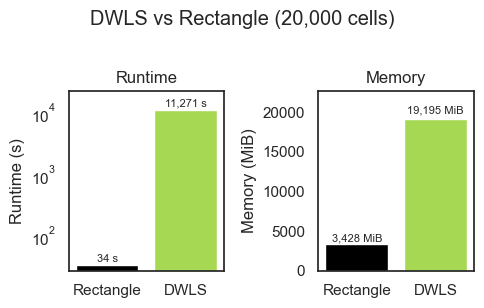

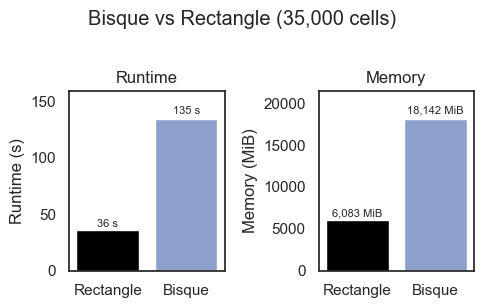

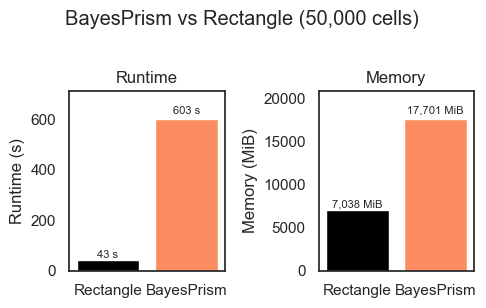

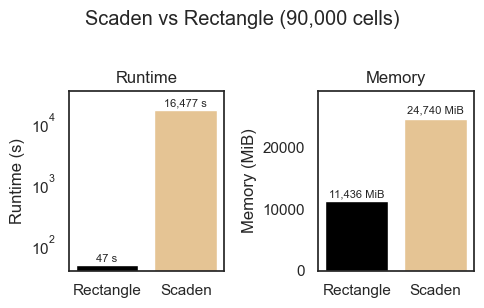

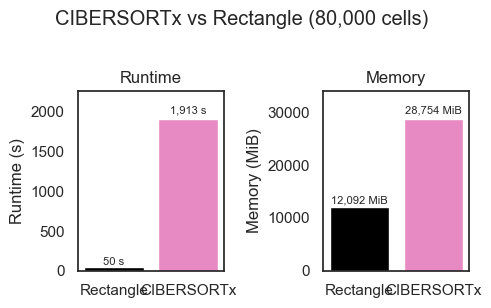

In [79]:
"""
rect_mem = pd.read_csv('../data/fig2/runtimes/rectangle_memory_summary.csv')
rect_run = pd.read_csv('../data/fig2/runtimes/rectangle_runtime_summary.csv')

scaden = pd.read_csv('../data/fig2/runtimes/scaden.csv')
dwls = pd.read_csv('../data/fig2/runtimes/dwls_benchmark_results.csv')
bisque = pd.read_csv('../data/fig2/runtimes/bisque_benchmark_results.csv')
bayesprism = pd.read_csv('../data/fig2/runtimes/bayesprism_benchmark_results.csv')
cibersortx_runtime = pd.read_csv('../data/fig2/runtimes/cibersortx_runtime_80k.csv')
cibersortx_memory = pd.read_csv('../data/fig2/runtimes/cibersortx_memory_80k.csv')

target_cells = {
    'DWLS': 20000,
    'Bisque': 35000,
    'BayesPrism': 50000,
    'Scaden': 90000,
    'CIBERSORTx': 80000,
}
failing_data = {
    'DWLS': dwls,
    'Bisque': bisque,
    'BayesPrism': bayesprism,
    'Scaden': scaden,
    'CIBERSORTx': None,
}

# Same palette as Figure 3C
method_to_color = {
    'Rectangle': '#000000',
    'SCDC': '#B3B3B3',
    'Autogenes': '#66C2A5',
    'MuSiC': '#FFD92F',
    'Scaden': '#E5C494',
    'BayesPrism': '#FC8D62',
    'Bisque': '#8DA0CB',
    'DWLS': '#A6D854',
    'CIBERSORTx': '#E78AC3',
}

methods = ['DWLS', 'Bisque', 'BayesPrism', 'Scaden', 'CIBERSORTx']

def get_rectangle_row(df, n_cells):
    exact = df.loc[df['n_cells'] == n_cells]
    if not exact.empty:
        return exact.iloc[0], int(n_cells)
    nearest_idx = (df['n_cells'] - n_cells).abs().idxmin()
    return df.loc[nearest_idx], int(df.loc[nearest_idx, 'n_cells'])

def annotate_bars(ax, bars, fmt, y_scale='linear'):
    for bar in bars:
        h = bar.get_height()
        if y_scale == 'log':
            y = h * 1.05
            va = 'bottom'
        else:
            y = h * 1.02
            va = 'bottom'
        ax.text(bar.get_x() + bar.get_width() / 2, y, fmt(h), ha='center', va=va, fontsize=8)

for method in methods:
    n_cells = target_cells[method]
    rect_run_row, rect_cells_run = get_rectangle_row(rect_run, n_cells)
    rect_mem_row, rect_cells_mem = get_rectangle_row(rect_mem, n_cells)
    rect_cells_used = rect_cells_run if rect_cells_run == rect_cells_mem else min(rect_cells_run, rect_cells_mem)

    method_df = failing_data[method]
    if method == 'CIBERSORTx':
        method_runtime_mean = cibersortx_runtime['time'].mean()
        method_memory_mean = cibersortx_memory['memory_mib'].mean()
    else:
        method_runtime_mean = method_df['Time_s'].mean()
        method_memory_mean = method_df['Peak_Mem_MiB'].mean()

    if method == 'DWLS' and method_memory_mean > 1e6:
        method_memory_mean = method_memory_mean * 8 / (1024 * 1024)

    fig, axes = plt.subplots(1, 2, figsize=(5, 3))
    bar_labels = ['Rectangle', method]

    bars_runtime = axes[0].bar(
        bar_labels,
        [rect_run_row['time_mean'], method_runtime_mean],
        color=[method_to_color['Rectangle'], method_to_color[method]],
    )
    axes[0].set_ylabel('Runtime (s)')
    axes[0].set_title(f'Runtime')
    runtime_vals = [rect_run_row['time_mean'], method_runtime_mean]
    if method in ['Bisque', 'BayesPrism', 'CIBERSORTx']:
        axes[0].set_ylim(0, max(runtime_vals) * 1.18)
        annotate_bars(axes[0], bars_runtime, lambda x: f'{x:,.0f} s')
    else:
        axes[0].set_yscale('log')
        axes[0].set_ylim(min(runtime_vals) * 0.8, max(runtime_vals) * 2.0)
        annotate_bars(axes[0], bars_runtime, lambda x: f'{x:,.0f} s', y_scale='log')

    bars_memory = axes[1].bar(
        bar_labels,
        [rect_mem_row['memory_mean'], method_memory_mean],
        color=[method_to_color['Rectangle'], method_to_color[method]],
    )
    axes[1].set_ylabel('Memory (MiB)')
    axes[1].set_title(f'Memory')
    memory_vals = [rect_mem_row['memory_mean'], method_memory_mean]
    axes[1].set_ylim(0, max(memory_vals) * 1.18)
    annotate_bars(axes[1], bars_memory, lambda x: f'{x:,.0f} MiB')

    if rect_cells_used == n_cells:
        fig.suptitle(f'{method} vs Rectangle ({n_cells:,} cells)', y=1.02)
    else:
        fig.suptitle(f'{method} ({n_cells:,}) vs Rectangle ({rect_cells_used:,} cells)', y=1.02)
    plt.tight_layout()
    plt.show()
"""

Panel A: fig2a_method_dataset_rmse_stacked.pdf
Panel B: fig2bc_rectangle_comparison_20k_no_log.pdf
Panel C: fig2bc_rectangle_comparison_20k_no_log.pdf
Panels D, E: fig2d_rectangle_runtime_memory_phases.pdf
Saved /Users/berni/PycharmProjects/rectangle_paper/figures/fig2_combined.pdf
Saved /Users/berni/PycharmProjects/rectangle_paper/figures/fig2_combined.png


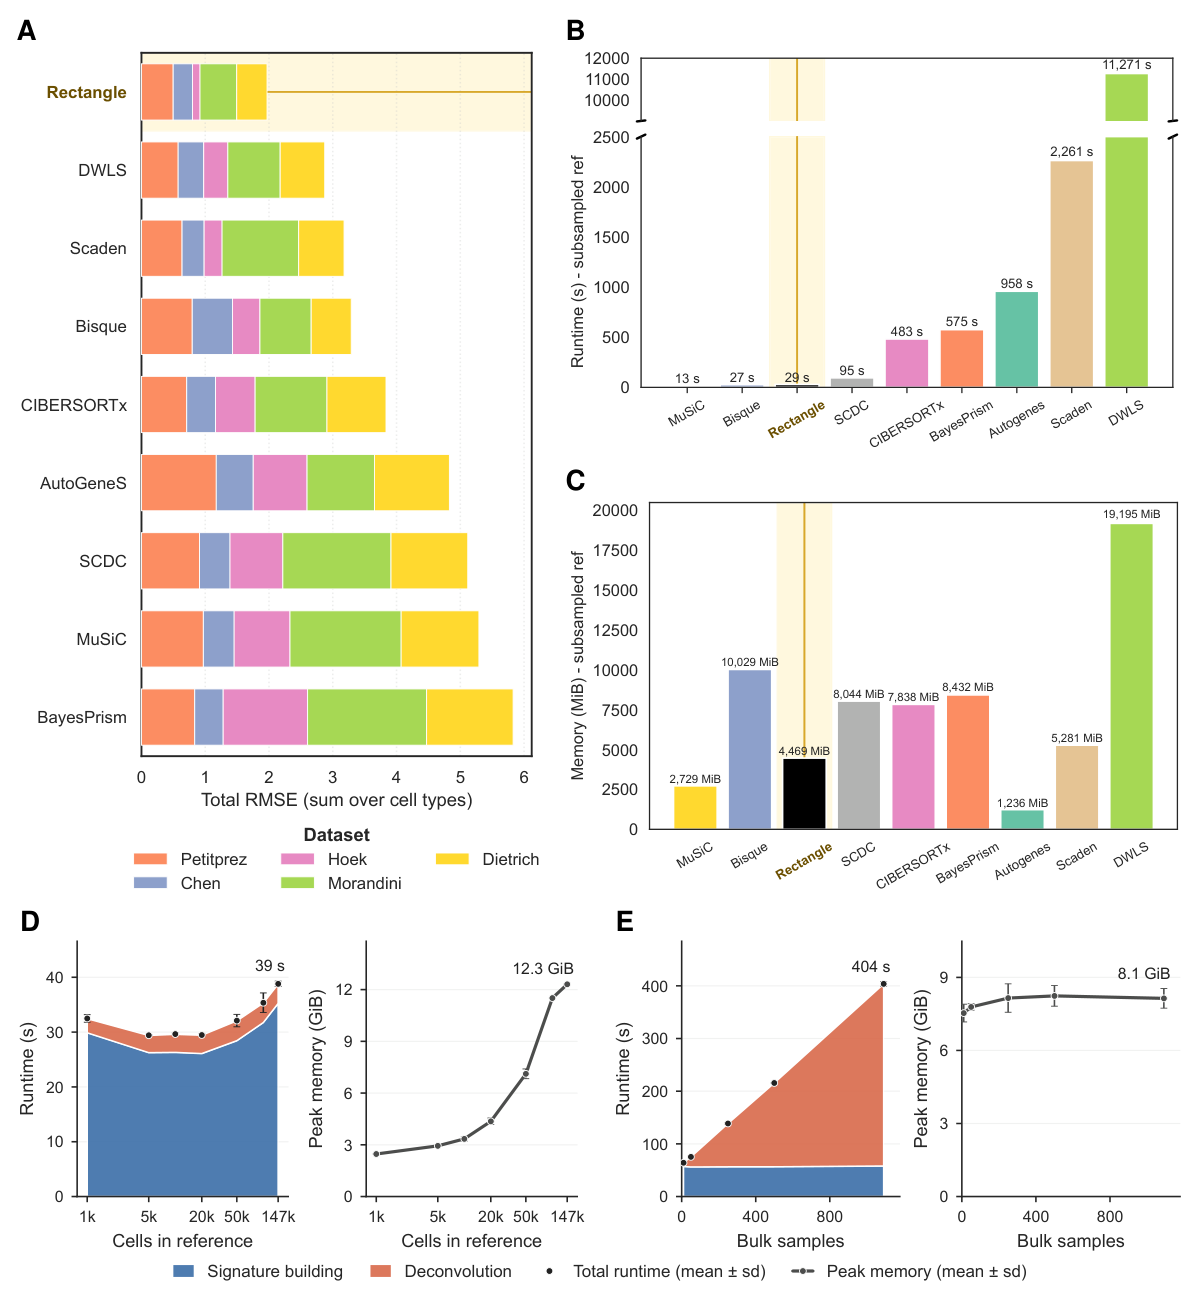

In [8]:
# Assemble Figure 2 from saved plots; no data or earlier kernel variables needed.
from pathlib import Path
from contextlib import ExitStack
import json
import pymupdf
import numpy as np
from IPython.display import Image, display

# Works when the notebook kernel starts in notebooks/ or the project root.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks' / 'figure_2.ipynb').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Run this cell from the rectangle_paper project or its notebooks directory.')
figure_dir = project_root / 'figures'
panel_files = {
    'A': figure_dir / 'fig2a_method_dataset_rmse_stacked.pdf',
    'BC': figure_dir / 'fig2bc_rectangle_comparison_20k_no_log.pdf',
    'D': figure_dir / 'fig2d_rectangle_runtime_memory_phases.pdf',
}
# The bottom row holds two panels (D: reference size, E: bulk samples); its figure cell records where E starts
bottom_row_layout = figure_dir / 'fig2d_rectangle_runtime_memory_phases_layout.json'
missing_files = [str(path) for path in [*panel_files.values(), bottom_row_layout] if not path.is_file()]
if missing_files:
    raise FileNotFoundError('Missing saved panel PDFs: ' + ', '.join(missing_files))
bottom_row_x = json.loads(bottom_row_layout.read_text())['group_x_fractions']

pdf_path = figure_dir / 'fig2_combined.pdf'
png_path = figure_dir / 'fig2_combined.png'
with ExitStack() as stack:
    sources = {
        key: stack.enter_context(pymupdf.open(path))
        for key, path in panel_files.items()
    }
    for key, document in sources.items():
        if len(document) != 1:
            raise ValueError(f'Panel {key} must be a single-page PDF: {panel_files[key]}')

    def content_clip(document, region=None, padding=3):
        # Detect visible content at modest resolution; embed the original vectors.
        region = document[0].rect if region is None else region
        pix = document[0].get_pixmap(
            matrix=pymupdf.Matrix(2, 2), clip=region, alpha=False,
        )
        pixels = np.frombuffer(pix.samples, dtype=np.uint8).reshape(
            pix.height, pix.width, pix.n,
        )
        rows, columns = np.nonzero(np.any(pixels[:, :, :3] < 245, axis=2))
        if not len(rows):
            raise ValueError('A saved panel contains no visible content.')
        bounds = pymupdf.Rect(
            (pix.x + columns.min()) / 2 - padding,
            (pix.y + rows.min()) / 2 - padding,
            (pix.x + columns.max() + 1) / 2 + padding,
            (pix.y + rows.max() + 1) / 2 + padding,
        )
        return bounds & region

    # Split B/C in the central gutter, then trim each panel independently.
    bc_rect = sources['BC'][0].rect
    bc_split = bc_rect.width * 0.50
    clips = {
        'A': content_clip(sources['A']),
        'B': content_clip(sources['BC'], pymupdf.Rect(0, 0, bc_split, bc_rect.height)),
        'C': content_clip(sources['BC'], pymupdf.Rect(bc_split, 0, bc_rect.width, bc_rect.height)),
        # Saved tight by its cell; the full page keeps the recorded group positions valid
        'D': sources['D'][0].rect,
    }
    ratios = {letter: clip.height / clip.width for letter, clip in clips.items()}

    # Fit the columns to their content so A and C finish at the same height.
    page_width = 864
    margin, column_gap, row_gap, label_height = 12, 16, 10, 22
    available_width = page_width - 2 * margin
    column_width = available_width - column_gap
    right_ratio = ratios['B'] + ratios['C']
    left_width = (
        right_ratio * column_width + row_gap + label_height
    ) / (ratios['A'] + right_ratio)
    right_width = column_width - left_width
    left_x, right_x = margin, margin + left_width + column_gap
    top_y = margin + label_height
    upper_height = left_width * ratios['A']
    c_y = top_y + right_width * ratios['B'] + row_gap + label_height
    d_y = top_y + upper_height + row_gap + label_height
    page_height = d_y + available_width * ratios['D'] + margin
    panels = {
        'A': ('A', left_x, top_y, left_width),
        'B': ('BC', right_x, top_y, right_width),
        'C': ('BC', right_x, c_y, right_width),
        'D': ('D', margin, d_y, available_width),
    }

    combined = stack.enter_context(pymupdf.open())
    page = combined.new_page(width=page_width, height=page_height)
    page.draw_rect(page.rect, color=None, fill=(1, 1, 1), overlay=False)
    for letter, (source_key, x, y, width) in panels.items():
        bounds = pymupdf.Rect(x, y, x + width, y + width * ratios[letter])
        page.show_pdf_page(
            bounds, sources[source_key], 0,
            clip=clips[letter], keep_proportion=True,
        )
        if letter == 'D':
            for group_letter, x_fraction in zip('DE', bottom_row_x):
                page.insert_text((x + x_fraction * width, y - 5), group_letter, fontsize=20, fontname='hebo')
            print(f'Panels D, E: {panel_files[source_key].name}', flush=True)
        else:
            page.insert_text((x, y - 5), letter, fontsize=20, fontname='hebo')
            print(f'Panel {letter}: {panel_files[source_key].name}', flush=True)

    combined.save(pdf_path, garbage=4, deflate=True)
    page.get_pixmap(dpi=300, alpha=False).save(png_path)
    preview_png = page.get_pixmap(dpi=100, alpha=False).tobytes('png')

print(f'Saved {pdf_path}')
print(f'Saved {png_path}')
display(Image(data=preview_png))
